# TCC — Análise comparativa de algoritmos de ML para detecção de ataques em redes IoT (IoT-23)

**Aluno:** Murilo Kaemmerer Klein · **Orientador:** Prof. Marco Antonio Sandini Trentin

Este notebook segue a ordem das etapas da proposta (Seção 4.2).

| Seção | Etapa da proposta | Status |
|---|---|---|
| 1 | Configuração do ambiente | ✅ |
| 2 | Etapa 1 — Seleção, pré-processamento e análise exploratória | ✅ |
| 3 | Etapa 2 — Divisão treino/teste, normalização e balanceamento | ✅ |
| 4 | Etapa 3 — Implementação dos modelos (RF, AD, SVM) | ✅ · CNN ⬜ |
| 5 | Etapa 4 — Ajuste de hiperparâmetros | SVM ✅ · RF/AD ⬜ · CNN ⬜ |
| 6 | Etapa 5 — Avaliação e comparação | CV, inferência, McNemar ✅ · Wilcoxon ⬜ |
| 7 | Experimentos complementares (validade — Seção 4.4) | ✅ |

**Como rodar:** execute de cima para baixo (*Runtime → Run all*). As etapas caras usam *cache* no Drive:
- o carregamento dos logs brutos (~8 GB de RAM) só roda se `REPROCESSAR_DADOS_BRUTOS = True` ou se o checkpoint amostrado não existir;
- os modelos SVM, o tuning e a validação cruzada do SVM ficam salvos no Drive e são recarregados.

## 1. Configuração do ambiente

In [1]:
# 1.1 — Imports (todos concentrados aqui)
import os, gc, json, time, hashlib, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, precision_recall_fscore_support)
from imblearn.over_sampling import SMOTE
from statsmodels.stats.contingency_tables import mcnemar

In [2]:
# 1.2 — Google Colab: Drive + repositório Git
from google.colab import userdata, drive

drive.mount('/content/drive')

token = userdata.get('GITHUB_TOKEN')
usuario = "muriloklein"
repo = "tcc"
if not os.path.exists("/content/tcc"):
    !git clone https://{token}@github.com/{usuario}/{repo}.git
%cd /content/tcc

# !git config --global user.email "eu.murilok@gmail.com"
# !git config --global user.name "Murilo Klein"
# !pip install imbalanced-learn --quiet

Mounted at /content/drive
Cloning into 'tcc'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (60/60), done.
remote: Total 91 (delta 37), reused 77 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (91/91), 629.47 KiB | 2.46 MiB/s, done.
Resolving deltas: 100% (37/37), done.
/content/tcc


In [3]:
# 1.3 — Caminhos, constantes e flags (tudo que é "configuração" fica só aqui)
BASE_DIR      = "/content/drive/MyDrive/TCC"
DADOS_DIR     = f"{BASE_DIR}/dados/raw"                # logs brutos do IoT-23
PROCESSED_DIR = f"{BASE_DIR}/dados/processed"          # checkpoints parquet + scaler
FIGURAS_DIR   = f"{BASE_DIR}/resultados/figuras"       # figuras para o texto
TABELAS_DIR   = f"{BASE_DIR}/resultados/tabelas"       # CSVs de resultados para o texto
MODELOS_DIR   = f"{BASE_DIR}/modelos"                  # cache de modelos e hiperparâmetros
PRED_DIR      = f"{BASE_DIR}/resultados/predicoes"     # cache de predições no teste
CV_DIR        = f"{BASE_DIR}/resultados/cv_svm"        # cache da CV do SVM (por fold)
for d in (DADOS_DIR, PROCESSED_DIR, FIGURAS_DIR, TABELAS_DIR, MODELOS_DIR, PRED_DIR, CV_DIR):
    os.makedirs(d, exist_ok=True)

# Checkpoints
CAMINHO_BRUTO     = f"{PROCESSED_DIR}/dataset_completo_bruto_v1.parquet"   # tudo, antes da dedup
CAMINHO_AMOSTRADO = f"{PROCESSED_DIR}/dataset_amostrado_v1.parquet"        # após dedup + teto por classe
CAMINHO_ENCODED   = f"{PROCESSED_DIR}/dataset_encoded_v1.parquet"          # após limpeza + one-hot

# Parâmetros do experimento
RANDOM_STATE     = 42
CAP_POR_CLASSE   = 20_000      # teto de linhas únicas por classe
CLASSES_SEM_TETO = {"benign"}  # o benigno entra inteiro
LIMIAR_HISTORY   = 500         # categorias de 'history' com menos ocorrências viram "outros"
TEST_SIZE        = 0.30

# Flags de execução
REPROCESSAR_DADOS_BRUTOS = False   # True = recarrega os 21 mi de linhas brutas (lento, ~8 GB RAM)
RETREINAR_SVM            = False   # True = ignora o cache dos SVMs e treina de novo (horas)

# Colunas
COLUNAS_NUMERICAS   = ["id.orig_p", "id.resp_p", "duration", "orig_bytes",
                       "resp_bytes", "missed_bytes", "orig_pkts", "resp_pkts"]
COLUNAS_ONEHOT      = ["proto", "service", "conn_state", "history"]
COLUNAS_NAO_FEATURE = ["label", "detailed-label", "origem_cenario"]   # alvos + metadado

RF_KWARGS = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

In [4]:
# 1.4 — Funções utilitárias (reutilizadas em todo o notebook)

def rotulo_multiclasse(detailed_label):
    """Benignos têm detailed-label vazio: vira 'benign'."""
    return detailed_label.astype("string").fillna("benign")


def salvar_figura(nome_arquivo):
    plt.savefig(os.path.join(FIGURAS_DIR, nome_arquivo), dpi=300, bbox_inches="tight")


def salvar_tabela(df, nome_arquivo):
    caminho = os.path.join(TABELAS_DIR, nome_arquivo)
    df.to_csv(caminho, index=False)
    print(f"[tabela] {caminho}")


# ---------- Pré-processamento (fonte única: usado no pipeline principal E nos experimentos) ----------
def tratar_ausentes(df):
    df = df.copy()
    df = df.drop(columns=["local_orig", "local_resp"])            # 100% vazias
    for col in ["duration", "orig_bytes", "resp_bytes"]:
        df[f"{col}_ausente"] = df[col].isna()                     # indicador antes de preencher
    df[["duration", "orig_bytes", "resp_bytes"]] = df[["duration", "orig_bytes", "resp_bytes"]].fillna(0)
    for col in ["service", "history"]:
        if df[col].dtype.name == "category":
            df[col] = df[col].cat.add_categories(["desconhecido"])
        df[col] = df[col].fillna("desconhecido")
    return df


def reduzir_e_codificar(df, categorias_history=None):
    """Remove redundantes, agrupa 'history' raros e aplica one-hot.
    categorias_history=None -> aprende as categorias frequentes com os próprios dados.
    Passe uma lista para reaproveitar o vocabulário de outro conjunto (ex.: teste externo)."""
    df = df.drop(columns=["resp_ip_bytes", "orig_ip_bytes"])      # correlação ~1 com resp/orig_bytes
    if categorias_history is None:
        contagem = df["history"].value_counts()
        categorias_history = [str(c) for c in contagem[contagem >= LIMIAR_HISTORY].index]
    df["history"] = df["history"].astype("string")
    df["history"] = df["history"].where(df["history"].isin(categorias_history), "outros")
    df_enc = pd.get_dummies(df, columns=COLUNAS_ONEHOT, prefix=COLUNAS_ONEHOT, dtype="int8")
    return df_enc, categorias_history


def preprocessar_features(df, categorias_history=None):
    return reduzir_e_codificar(tratar_ausentes(df), categorias_history)


def separar_X_y(df_enc):
    X = df_enc.drop(columns=[c for c in COLUNAS_NAO_FEATURE if c in df_enc.columns])
    return X, df_enc["label"], rotulo_multiclasse(df_enc["detailed-label"])


def normalizar(X_tr, X_te):
    """StandardScaler só nas colunas numéricas; fit no treino, transform no teste."""
    scaler = StandardScaler()
    X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
    X_tr_n[COLUNAS_NUMERICAS] = scaler.fit_transform(X_tr[COLUNAS_NUMERICAS])
    X_te_n[COLUNAS_NUMERICAS] = scaler.transform(X_te[COLUNAS_NUMERICAS])
    return X_tr_n, X_te_n, scaler


def sobreposicao(X_tr, X_te):
    """Quantas linhas do teste têm vetor de features idêntico a alguma linha do treino (via hash)."""
    hashes_treino = set(pd.util.hash_pandas_object(X_tr, index=False))
    no_treino = pd.util.hash_pandas_object(X_te, index=False).isin(hashes_treino)
    return int(no_treino.sum()), float(no_treino.mean() * 100)


# ---------- Treino / avaliação ----------
def treinar_avaliar(titulo, modelo, X_tr, y_tr, X_te, y_te, nome_cache=None, retreinar=False):
    """Treina, prediz no teste e imprime o classification_report.
    Com nome_cache: salva/recarrega modelo e predições no Drive (usado nos SVMs, que levam horas).
    Retorna (modelo, y_pred, tempo_treino_s)."""
    y_pred = None
    if nome_cache:
        caminho_modelo = f"{MODELOS_DIR}/{nome_cache}.joblib"
        caminho_pred   = f"{PRED_DIR}/{nome_cache}_pred.npy"

    if nome_cache and os.path.exists(caminho_modelo) and not retreinar:
        salvo = joblib.load(caminho_modelo)
        modelo, tempo_treino = salvo["modelo"], salvo["tempo_treino"]
        print(f"[cache] modelo carregado: {caminho_modelo}")
        if getattr(modelo, "n_features_in_", X_te.shape[1]) != X_te.shape[1]:
            raise RuntimeError(f"{nome_cache}: modelo em cache espera {modelo.n_features_in_} features, "
                               f"mas X tem {X_te.shape[1]}. Os dados mudaram — use retreinar=True.")
    else:
        t0 = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        tempo_treino = time.perf_counter() - t0
        if nome_cache:
            joblib.dump({"modelo": modelo, "tempo_treino": tempo_treino}, caminho_modelo)
            if os.path.exists(caminho_pred):
                os.remove(caminho_pred)          # predição antiga não vale mais

    if nome_cache and os.path.exists(caminho_pred):
        y_pred = np.load(caminho_pred)
        # Checagem de consistência: o cache precisa corresponder ao conjunto de teste ATUAL
        n = min(50, len(X_te))
        if len(y_pred) != len(y_te) or not np.array_equal(
                np.asarray(modelo.predict(X_te.iloc[:n]), dtype=str), y_pred[:n]):
            raise RuntimeError(f"{nome_cache}: predições em cache não batem com o teste atual. "
                               "Os dados mudaram — use retreinar=True.")
    else:
        y_pred = np.asarray(modelo.predict(X_te), dtype=str)
        if nome_cache:
            np.save(caminho_pred, y_pred)

    print(f"\n=== {titulo} === (treino: {tempo_treino:.2f}s)")
    print(classification_report(y_te, y_pred, digits=4, zero_division=0))
    return modelo, y_pred, tempo_treino


def plotar_matriz_confusao(y_true, y_pred, labels, titulo, nome_arquivo):
    matriz = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(9, 7))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(titulo); plt.xlabel("Classe prevista"); plt.ylabel("Classe real")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    salvar_figura(nome_arquivo)
    plt.show()
    return matriz


def subamostra_estratificada(y, cap_padrao=3000, caps=None, seed=RANDOM_STATE):
    """Índices POSICIONAIS (.iloc). Classes pequenas entram inteiras; grandes são cortadas."""
    rng = np.random.default_rng(seed)
    y_arr = np.asarray(y.astype(str))
    caps = caps or {}
    partes = []
    for classe in np.unique(y_arr):
        pos = np.where(y_arr == classe)[0]
        n = min(len(pos), caps.get(classe, cap_padrao))
        partes.append(rng.choice(pos, size=n, replace=False))
    return np.sort(np.concatenate(partes))


# ---------- Acesso ao checkpoint bruto (experimentos da Seção 7) ----------
def contar_classes_bruto(caminho=CAMINHO_BRUTO):
    """Contagem REAL de linhas por classe no dataset bruto (substitui contagens digitadas à mão)."""
    col = ds.dataset(caminho, format="parquet").to_table(columns=["detailed-label"]) \
            .column("detailed-label").to_pandas()
    vc = col.value_counts(dropna=False)
    return {("benign" if pd.isna(k) else str(k)): int(v) for k, v in vc.items() if v > 0}


def amostrar_classe_bruto(dataset, classe, p_manter, rng):
    """Amostragem de Bernoulli de uma classe, lendo o parquet em lotes (não estoura a RAM)."""
    filtro = pc.field("detailed-label").is_null() if classe == "benign" \
             else (pc.field("detailed-label") == classe)
    lotes = []
    for lote in dataset.to_batches(filter=filtro, batch_size=200_000):
        if lote.num_rows == 0:
            continue
        mascara = rng.random(lote.num_rows) < p_manter
        if mascara.any():
            lotes.append(lote.take(np.nonzero(mascara)[0]))
    return pa.Table.from_batches(lotes).to_pandas() if lotes else pd.DataFrame()

print("Ambiente pronto.")

Ambiente pronto.


## 2. Etapa 1 — Seleção e pré-processamento dos dados

Cenários do IoT-23 usados (9 capturas): 6 maliciosos (34-1, 36-1, 9-1, 8-1, 3-1, 1-1) e 3 benignos (Honeypot 4-1, 5-1, 7-1).

Ordem do pipeline:
1. download → 2. carregamento → 3. **deduplicação por classe e depois** teto de 20.000 linhas/classe →
4. valores ausentes → 5. análise exploratória → 6. remoção de redundantes, agrupamento de `history` e one-hot.

In [5]:
# 2.1 — Download dos conn.log.labeled (pula os que já existem no Drive)
URL_BASE = "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/IndividualScenarios"

# A ORDEM deste dicionário é a ordem de concatenação — não altere, pois ela define
# qual linha é mantida na deduplicação (keep="first") e, portanto, a amostra final.
CENARIOS = {
    "capture_34_1_DDoS_PortScan":       f"{URL_BASE}/CTU-IoT-Malware-Capture-34-1/bro/conn.log.labeled",
    "capture_36_1_Okiru":               f"{URL_BASE}/CTU-IoT-Malware-Capture-36-1/bro/conn.log.labeled",
    "capture_9_1_PortScan":             f"{URL_BASE}/CTU-IoT-Malware-Capture-9-1/bro/conn.log.labeled",
    "capture_4_1_Benign_Honeypot":      f"{URL_BASE}/CTU-Honeypot-Capture-4-1/bro/conn.log.labeled",
    "capture_5_1_Benign_Honeypot":      f"{URL_BASE}/CTU-Honeypot-Capture-5-1/bro/conn.log.labeled",
    "capture_7_1_Benign_Honeypot":      f"{URL_BASE}/CTU-Honeypot-Capture-7-1/Somfy-01/bro/conn.log.labeled",
    "capture_8_1_CC_Hakai":             f"{URL_BASE}/CTU-IoT-Malware-Capture-8-1/bro/conn.log.labeled",
    "capture_3_1_Attack_Muhstik":       f"{URL_BASE}/CTU-IoT-Malware-Capture-3-1/bro/conn.log.labeled",
    "capture_1_1_PortScan_HideAndSeek": f"{URL_BASE}/CTU-IoT-Malware-Capture-1-1/bro/conn.log.labeled",
}
# Linhas descartadas por cenário (okiru-attack: rótulo residual do 36-1)
EXCLUIR_DETAILED_LABEL = {"capture_36_1_Okiru": "okiru-attack"}

def caminho_log(nome):
    return os.path.join(DADOS_DIR, f"{nome}.log.labeled")

for nome, url in CENARIOS.items():
    destino = caminho_log(nome)
    if os.path.exists(destino):
        print(f"[OK] {nome} já existe, pulando download.")
        continue
    print(f"Baixando {nome}...")
    try:
        urllib.request.urlretrieve(url, destino)
        print(f"[OK] {nome} salvo em {destino}")
    except Exception as e:
        print(f"[ERRO] Falha ao baixar {nome}: {e}")

PRECISA_PROCESSAR_BRUTO = REPROCESSAR_DADOS_BRUTOS or not os.path.exists(CAMINHO_AMOSTRADO)
print("\nProcessar dados brutos nesta execução?", PRECISA_PROCESSAR_BRUTO)

[OK] capture_34_1_DDoS_PortScan já existe, pulando download.
[OK] capture_36_1_Okiru já existe, pulando download.
[OK] capture_9_1_PortScan já existe, pulando download.
[OK] capture_4_1_Benign_Honeypot já existe, pulando download.
[OK] capture_5_1_Benign_Honeypot já existe, pulando download.
[OK] capture_7_1_Benign_Honeypot já existe, pulando download.
[OK] capture_8_1_CC_Hakai já existe, pulando download.
[OK] capture_3_1_Attack_Muhstik já existe, pulando download.
[OK] capture_1_1_PortScan_HideAndSeek já existe, pulando download.

Processar dados brutos nesta execução? False


In [6]:
# 2.2 — Carregamento dos logs (só se necessário) + checkpoint bruto
# Nomes de coluna do conn.log do Zeek + as 2 colunas extras do IoT-23
COLUNAS_COMPLETAS = [
    "ts", "uid", "id.orig_h", "id.orig_p", "id.resp_h", "id.resp_p",
    "proto", "service", "duration", "orig_bytes", "resp_bytes",
    "conn_state", "local_orig", "local_resp", "missed_bytes",
    "history", "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes",
    "tunnel_parents", "label", "detailed-label",
]
# Identificadores (ts, uid, IPs) e tunnel_parents não são carregados: evitam data leakage
COLUNAS_USADAS = [
    "id.orig_p", "id.resp_p", "proto", "service", "duration",
    "orig_bytes", "resp_bytes", "conn_state", "local_orig", "local_resp",
    "missed_bytes", "history", "orig_pkts", "orig_ip_bytes",
    "resp_pkts", "resp_ip_bytes", "label", "detailed-label",
]
DTYPE_OTIMIZADO = {   # 'category' e int32 reduzem drasticamente a RAM
    "proto": "category", "service": "category", "conn_state": "category",
    "local_orig": "category", "local_resp": "category", "history": "category",
    "label": "category", "detailed-label": "category",
    "id.orig_p": "int32", "id.resp_p": "int32", "missed_bytes": "int32",
    "orig_pkts": "int32", "orig_ip_bytes": "int32", "resp_pkts": "int32", "resp_ip_bytes": "int32",
}
CONFIG_LEITURA = {
    "sep": r"\s+",          # o header usa TAB, mas as últimas colunas às vezes vêm com espaço
    "comment": "#",         # ignora as linhas de cabeçalho do Zeek
    "header": None,
    "names": COLUNAS_COMPLETAS,
    "usecols": COLUNAS_USADAS,
    "na_values": "-",       # o Zeek usa "-" para ausente
    "dtype": DTYPE_OTIMIZADO,
}

def carregar_cenario(nome):
    df = pd.read_csv(caminho_log(nome), **CONFIG_LEITURA)
    df["label"] = df["label"].astype("string").str.lower().astype("category")
    df["detailed-label"] = df["detailed-label"].astype("string").str.lower().astype("category")
    if nome in EXCLUIR_DETAILED_LABEL:
        df = df[df["detailed-label"] != EXCLUIR_DETAILED_LABEL[nome]]
    origem = "_".join(nome.split("_")[:3])        # ex.: "capture_34_1"
    df["origem_cenario"] = origem
    print(f"{origem}: {df.shape} | {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB | "
          f"{df['label'].value_counts().to_dict()}")
    return df

if PRECISA_PROCESSAR_BRUTO:
    df_completo = pd.concat([carregar_cenario(n) for n in CENARIOS], ignore_index=True)
    gc.collect()
    # Checkpoint bruto (pré-dedup): usado nos experimentos de ablação da Seção 7
    df_completo.to_parquet(CAMINHO_BRUTO, index=False)
    print(f"\nCheckpoint bruto salvo em: {CAMINHO_BRUTO}")
    print(f"Formato: {df_completo.shape} | "
          f"{df_completo.memory_usage(deep=True).sum() / 1024**2:.0f} MB")
    print(df_completo["origem_cenario"].value_counts())
else:
    print("Checkpoint amostrado já existe — carregamento dos logs brutos pulado.")

Checkpoint amostrado já existe — carregamento dos logs brutos pulado.


In [7]:
# 2.3 — Deduplicação por classe ANTES do teto de amostragem + checkpoint amostrado
# Por que nessa ordem: amostrar primeiro e deduplicar depois colapsava classes muito
# repetitivas (okiru: 621 combinações únicas em 13,6 mi de linhas brutas virava só 2
# numa amostra aleatória de 20 mil). Deduplicando antes, classes com menos linhas
# únicas que o teto entram inteiras.
if PRECISA_PROCESSAR_BRUTO:
    df_completo["classe_amostra"] = rotulo_multiclasse(df_completo["detailed-label"])
    colunas_para_dedup = [c for c in df_completo.columns
                          if c not in ["label", "detailed-label", "origem_cenario", "classe_amostra"]]

    grupos_amostrados, resumo_dedup = [], []
    for classe, grupo in df_completo.groupby("classe_amostra", observed=True):
        linhas_brutas = len(grupo)
        grupo = grupo.drop_duplicates(subset=colunas_para_dedup, keep="first")
        linhas_unicas = len(grupo)
        if classe not in CLASSES_SEM_TETO and linhas_unicas > CAP_POR_CLASSE:
            grupo = grupo.sample(n=CAP_POR_CLASSE, random_state=RANDOM_STATE)
        resumo_dedup.append({"classe": classe, "linhas_brutas": linhas_brutas,
                             "linhas_unicas": linhas_unicas, "linhas_amostradas": len(grupo)})
        grupos_amostrados.append(grupo)

    df_amostrado = pd.concat(grupos_amostrados, ignore_index=True).drop(columns=["classe_amostra"])
    del df_completo, grupos_amostrados
    gc.collect()

    df_resumo_dedup = pd.DataFrame(resumo_dedup)
    print(df_resumo_dedup.to_string(index=False))
    salvar_tabela(df_resumo_dedup, "resumo_dedup_por_classe.csv")
    df_amostrado.to_parquet(CAMINHO_AMOSTRADO, index=False)
    print(f"Checkpoint amostrado salvo em: {CAMINHO_AMOSTRADO}")

# Ponto de retomada: daqui para baixo tudo parte do checkpoint amostrado (leve, ~2 MB)
df_amostrado = pd.read_parquet(CAMINHO_AMOSTRADO)
print(f"\nDataset amostrado: {df_amostrado.shape}")
print(rotulo_multiclasse(df_amostrado["detailed-label"]).value_counts())


Dataset amostrado: (176859, 19)
detailed-label
benign                       123538
partofahorizontalportscan     20000
c&c-heartbeat                 15687
c&c                           10827
attack                         5962
okiru                           621
ddos                            224
Name: count, dtype: Int64


In [8]:
# 2.4 — Valores ausentes
# - local_orig/local_resp: 100% vazias -> removidas
# - duration/orig_bytes/resp_bytes: indicador *_ausente + preenchimento com 0
# - service/history: categoria explícita "desconhecido"
df_limpo = tratar_ausentes(df_amostrado)
print(df_limpo.isna().sum()[lambda s: s > 0])   # só detailed-label (benignos) deve sobrar

detailed-label    123538
dtype: int64


### 2.5 — Análise exploratória

Feita **antes** de remover atributos, para que as decisões da etapa 2.6 (ex.: remoção de `orig_ip_bytes`/`resp_ip_bytes`) apareçam justificadas nos gráficos.

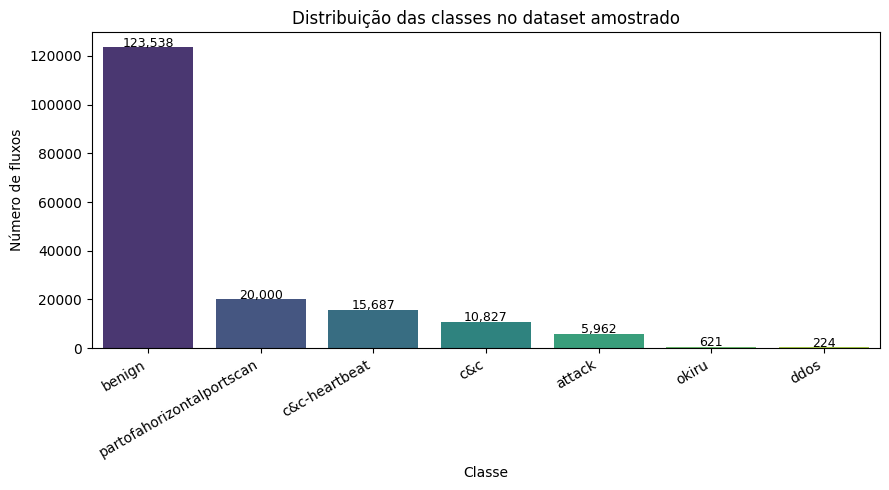

In [9]:
# Gráfico 1 — Distribuição de classes
df_plot = df_limpo.copy()
df_plot["classe_plot"] = rotulo_multiclasse(df_plot["detailed-label"])
contagem_classes = df_plot["classe_plot"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=contagem_classes.index, y=contagem_classes.values,
            hue=contagem_classes.index, palette="viridis", legend=False)
plt.title("Distribuição das classes no dataset amostrado")
plt.xlabel("Classe"); plt.ylabel("Número de fluxos"); plt.xticks(rotation=30, ha="right")
for i, valor in enumerate(contagem_classes.values):
    plt.text(i, valor + 300, f"{valor:,}", ha="center", fontsize=9)
plt.tight_layout(); salvar_figura("distribuicao_classes.png"); plt.show()

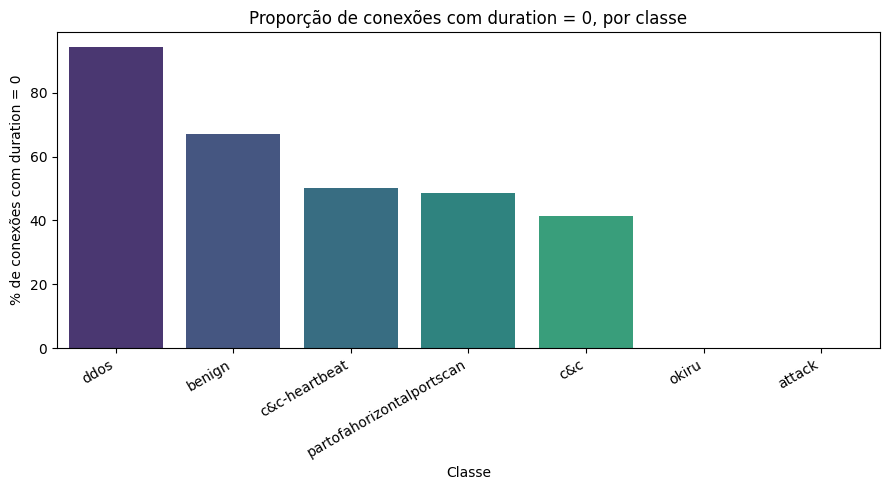

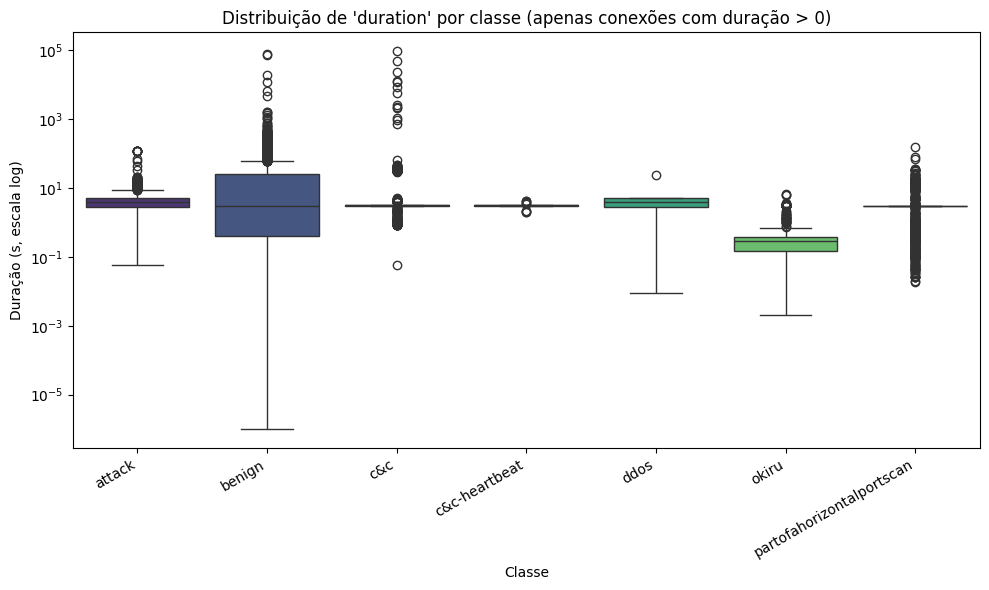

In [10]:
# Gráfico 2a — Proporção de conexões "instantâneas" (duration = 0) por classe
proporcao_zero = (df_plot["duration"] == 0).groupby(df_plot["classe_plot"]).mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=proporcao_zero.index, y=proporcao_zero.values * 100,
            hue=proporcao_zero.index, palette="viridis", legend=False)
plt.title("Proporção de conexões com duration = 0, por classe")
plt.xlabel("Classe"); plt.ylabel("% de conexões com duration = 0"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); salvar_figura("proporcao_duration_zero.png"); plt.show()

# Gráfico 2b — duration por classe, só conexões com duração > 0
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_plot[df_plot["duration"] > 0], x="classe_plot", y="duration",
            hue="classe_plot", palette="viridis", legend=False)
plt.yscale("log")
plt.title("Distribuição de 'duration' por classe (apenas conexões com duração > 0)")
plt.xlabel("Classe"); plt.ylabel("Duração (s, escala log)"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); salvar_figura("duration_por_classe_sem_zeros.png"); plt.show()

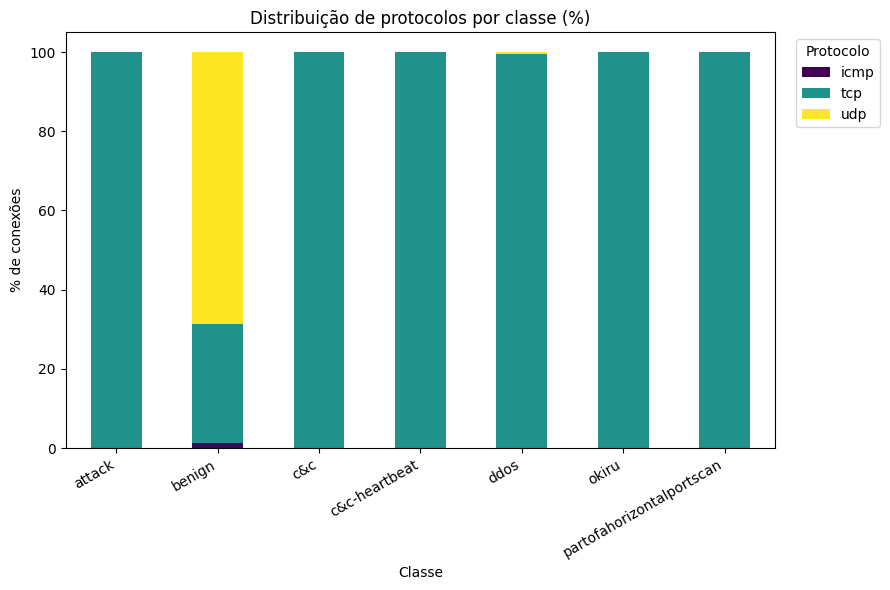

In [11]:
# Gráfico 3 — Protocolos por classe
tabela_proto = pd.crosstab(df_plot["classe_plot"], df_plot["proto"], normalize="index") * 100
plt.figure(figsize=(9, 6))
tabela_proto.plot(kind="bar", stacked=True, colormap="viridis", ax=plt.gca())
plt.title("Distribuição de protocolos por classe (%)")
plt.xlabel("Classe"); plt.ylabel("% de conexões"); plt.xticks(rotation=30, ha="right")
plt.legend(title="Protocolo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); salvar_figura("protocolo_por_classe.png"); plt.show()

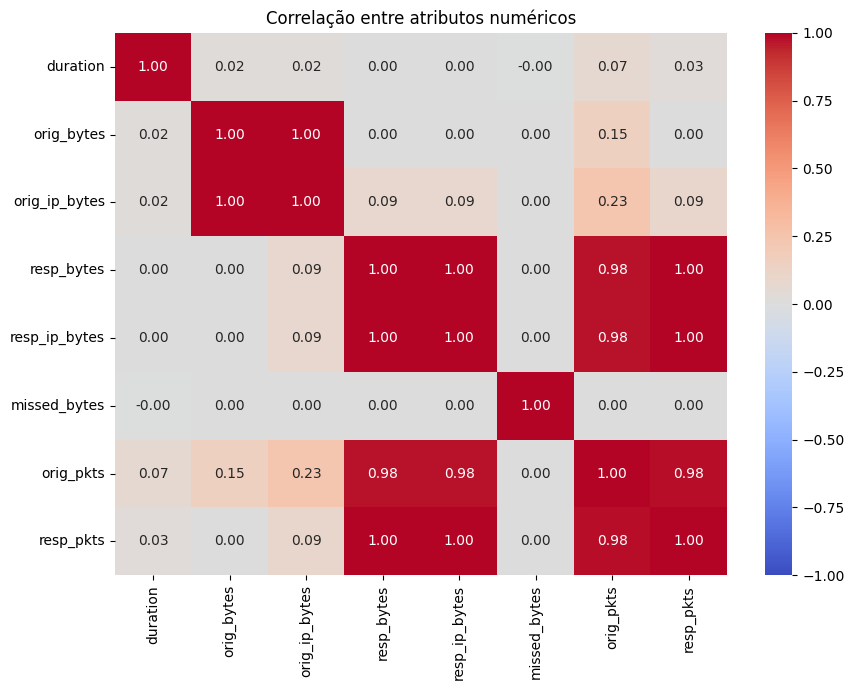

corr(orig_bytes, orig_ip_bytes) = 0.9963
corr(resp_bytes, resp_ip_bytes) = 1.0


In [12]:
# Gráfico 4 — Correlação entre atributos numéricos (inclui *_ip_bytes, que serão removidos em 2.6)
colunas_corr = ["duration", "orig_bytes", "orig_ip_bytes", "resp_bytes", "resp_ip_bytes",
                "missed_bytes", "orig_pkts", "resp_pkts"]
matriz_corr = df_limpo[colunas_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre atributos numéricos")
plt.tight_layout(); salvar_figura("correlacao_numericos.png"); plt.show()

print("corr(orig_bytes, orig_ip_bytes) =", round(matriz_corr.loc["orig_bytes", "orig_ip_bytes"], 4))
print("corr(resp_bytes, resp_ip_bytes) =", round(matriz_corr.loc["resp_bytes", "resp_ip_bytes"], 4))
del df_plot

In [13]:
# 2.6 — Remoção de redundantes + agrupamento de 'history' + one-hot  -> checkpoint encoded
df_encoded, CATEGORIAS_HISTORY = reduzir_e_codificar(df_limpo)

print(f"'history': {len(CATEGORIAS_HISTORY)} categorias mantidas (>= {LIMIAR_HISTORY} ocorrências): "
      f"{CATEGORIAS_HISTORY}; as demais viram 'outros'")
print(f"Formato: {df_limpo.shape} -> {df_encoded.shape}")

df_encoded.to_parquet(CAMINHO_ENCODED, index=False)
with open(f"{PROCESSED_DIR}/categorias_history_v1.json", "w") as f:   # vocabulário reaproveitável (ex.: CNN)
    json.dump(CATEGORIAS_HISTORY, f)
print(f"Checkpoint salvo em: {CAMINHO_ENCODED}")

'history': 7 categorias mantidas (>= 500 ocorrências): ['D', 'S', 'Sr', 'ShAdDaFf', 'Dd', 'desconhecido', 'ShAdDaf']; as demais viram 'outros'
Formato: (176859, 20) -> (176859, 45)
Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_encoded_v1.parquet


## 3. Etapa 2 — Divisão treino/teste, normalização e balanceamento

1. **Segunda deduplicação**, agora sobre o vetor final de features: a limpeza (preenchimento com 0, agrupamento de `history`, remoção de colunas) cria novas linhas idênticas, inclusive entre classes diferentes.
2. Split estratificado 70/30 (pelo rótulo multiclasse; o binário reaproveita os mesmos índices).
3. Normalização (fit só no treino).
4. Balanceamento: **SMOTE só na tarefa binária**; na multiclasse usa-se `class_weight='balanced'` (okiru/ddos têm pouquíssimas linhas únicas — interpolar entre elas não gera informação real).

In [14]:
# 3.1 — X / y + deduplicação final
X, y_binario, y_multiclasse = separar_X_y(df_encoded)

indices_unicos = X.drop_duplicates(keep="first").index
X_dedup = X.loc[indices_unicos]
y_binario_dedup = y_binario.loc[indices_unicos]
y_multiclasse_dedup = y_multiclasse.loc[indices_unicos]
origem_cenario_dedup = df_encoded.loc[indices_unicos, "origem_cenario"]   # usado na Seção 7

print(f"X: {X.shape} -> após dedup: {X_dedup.shape}")
print(y_multiclasse_dedup.value_counts())

X: (176859, 42) -> após dedup: (176572, 42)
detailed-label
benign                       123286
partofahorizontalportscan     19966
c&c-heartbeat                 15687
c&c                           10827
attack                         5962
okiru                           621
ddos                            223
Name: count, dtype: Int64


In [15]:
# 3.2 — Split estratificado 70/30
X_treino, X_teste, y_multi_treino, y_multi_teste = train_test_split(
    X_dedup, y_multiclasse_dedup, test_size=TEST_SIZE,
    random_state=RANDOM_STATE, stratify=y_multiclasse_dedup)
y_bin_treino = y_binario_dedup.loc[X_treino.index]
y_bin_teste  = y_binario_dedup.loc[X_teste.index]

n_overlap, pct_overlap = sobreposicao(X_treino, X_teste)
print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")
print(f"Linhas do teste idênticas a linhas do treino: {n_overlap} ({pct_overlap:.2f}%)")
assert n_overlap == 0, "Há vazamento treino/teste — revisar a deduplicação!"

print(pd.DataFrame({"treino": y_multi_treino.value_counts(normalize=True),
                    "teste":  y_multi_teste.value_counts(normalize=True)}).round(4))

Treino: (123600, 42) | Teste: (52972, 42)
Linhas do teste idênticas a linhas do treino: 0 (0.00%)
                           treino   teste
detailed-label                           
benign                     0.6982  0.6982
partofahorizontalportscan  0.1131  0.1131
c&c-heartbeat              0.0888  0.0888
c&c                        0.0613  0.0613
attack                     0.0338  0.0338
okiru                      0.0035  0.0035
ddos                       0.0013  0.0013


In [16]:
# 3.3 — Normalização (fit no treino, transform no teste)
X_treino_norm, X_teste_norm, scaler = normalizar(X_treino, X_teste)
joblib.dump(scaler, f"{PROCESSED_DIR}/scaler_v1.joblib")      # reaproveitável pela CNN
print(X_treino_norm[COLUNAS_NUMERICAS].describe().loc[["mean", "std"]].round(3))

      id.orig_p  id.resp_p  duration  orig_bytes  resp_bytes  missed_bytes  \
mean       -0.0        0.0       0.0        -0.0         0.0           0.0   
std         1.0        1.0       1.0         1.0         1.0           1.0   

      orig_pkts  resp_pkts  
mean       -0.0       -0.0  
std         1.0        1.0  


In [17]:
# 3.4 — Balanceamento
print("Treino multiclasse (sem SMOTE — balanceamento via class_weight):")
print(y_multi_treino.value_counts())

smote_bin = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_treino_smote_bin, y_bin_treino_smote = smote_bin.fit_resample(X_treino_norm, y_bin_treino)
print(f"\nBinário após SMOTE: {X_treino_smote_bin.shape}")
print(y_bin_treino_smote.value_counts())

Treino multiclasse (sem SMOTE — balanceamento via class_weight):
detailed-label
benign                       86300
partofahorizontalportscan    13976
c&c-heartbeat                10981
c&c                           7579
attack                        4173
okiru                          435
ddos                           156
Name: count, dtype: Int64

Binário após SMOTE: (172600, 42)
label
malicious    86300
benign       86300
Name: count, dtype: Int64


In [18]:
# 3.5 — Salva os conjuntos finais (já normalizados) + assinatura dos dados
X_treino_norm.assign(label=y_bin_treino, **{"detailed-label": y_multi_treino}) \
    .to_parquet(f"{PROCESSED_DIR}/treino_original_v1.parquet", index=False)
X_treino_smote_bin.assign(label=y_bin_treino_smote) \
    .to_parquet(f"{PROCESSED_DIR}/treino_smote_binario_v1.parquet", index=False)
X_teste_norm.assign(label=y_bin_teste, **{"detailed-label": y_multi_teste}) \
    .to_parquet(f"{PROCESSED_DIR}/teste_v1.parquet", index=False)

# Assinatura: se o pré-processamento mudar, os modelos em cache (SVM) deixam de valer.
def _hash(obj):
    return hashlib.sha256(pd.util.hash_pandas_object(obj, index=True).values.tobytes()).hexdigest()

assinatura = {"colunas": [str(c) for c in X_treino_norm.columns],
              "treino": _hash(X_treino_norm), "teste": _hash(X_teste_norm),
              "y_treino": _hash(y_multi_treino.astype(str)), "y_teste": _hash(y_multi_teste.astype(str))}
caminho_assinatura = f"{MODELOS_DIR}/assinatura_dados.json"
if os.path.exists(caminho_assinatura):
    with open(caminho_assinatura) as f:
        anterior = json.load(f)
    if anterior != assinatura and not RETREINAR_SVM:
        raise RuntimeError("Os dados de treino/teste mudaram desde que os modelos em cache foram treinados. "
                           "Defina RETREINAR_SVM = True (e apague as pastas modelos/, resultados/predicoes/ "
                           "e resultados/cv_svm/) para recalcular tudo.")
    print("Assinatura dos dados confere com a dos modelos em cache.")
if not os.path.exists(caminho_assinatura) or RETREINAR_SVM:
    with open(caminho_assinatura, "w") as f:
        json.dump(assinatura, f)
    print("Assinatura dos dados registrada.")
print("Conjuntos salvos em", PROCESSED_DIR)

Assinatura dos dados registrada.
Conjuntos salvos em /content/drive/MyDrive/TCC/dados/processed


## 4. Etapa 3 — Implementação dos modelos (hiperparâmetros padrão)

Cada algoritmo é treinado nas variantes:
- **binário + `class_weight`**, **binário + SMOTE**, **multiclasse + `class_weight`**.

O SVM+SMOTE binário foi executado uma única vez (resultado registrado em 4.3) e não é mais retreinado.

### 4.1 — Random Forest


=== Random Forest (binário) - class_weight === (treino: 6.63s)
              precision    recall  f1-score   support

      benign     0.9991    0.9988    0.9990     36986
   malicious     0.9972    0.9979    0.9976     15986

    accuracy                         0.9985     52972
   macro avg     0.9982    0.9984    0.9983     52972
weighted avg     0.9985    0.9985    0.9985     52972


=== Random Forest (binário) - SMOTE === (treino: 12.31s)
              precision    recall  f1-score   support

      benign     0.9993    0.9980    0.9987     36986
   malicious     0.9954    0.9984    0.9969     15986

    accuracy                         0.9981     52972
   macro avg     0.9974    0.9982    0.9978     52972
weighted avg     0.9982    0.9981    0.9982     52972


=== Random Forest (multiclasse) - class_weight === (treino: 8.88s)
                           precision    recall  f1-score   support

                   attack     0.9994    0.9989    0.9992      1789
                   be

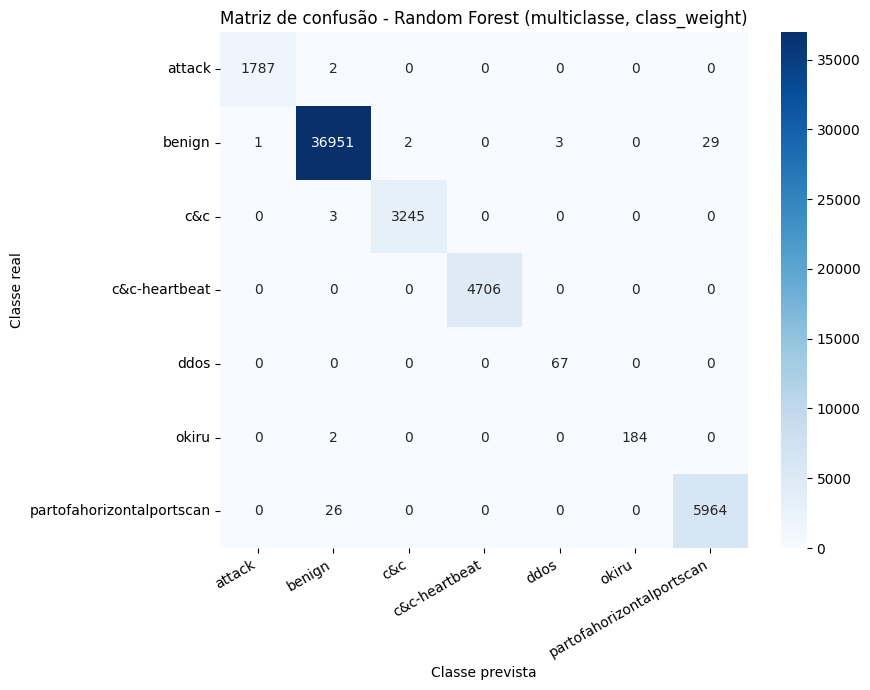

In [19]:
rf_binario_cw, y_pred_rf_bin_cw, tempo_rf_bin_cw = treinar_avaliar(
    "Random Forest (binário) - class_weight",
    RandomForestClassifier(class_weight="balanced", **RF_KWARGS),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste)

rf_binario_smote, y_pred_rf_bin_smote, tempo_rf_bin_smote = treinar_avaliar(
    "Random Forest (binário) - SMOTE",
    RandomForestClassifier(**RF_KWARGS),        # sem class_weight: SMOTE já balanceou
    X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste)

rf_multi_cw, y_pred_rf_multi_cw, tempo_rf_multi_cw = treinar_avaliar(
    "Random Forest (multiclasse) - class_weight",
    RandomForestClassifier(class_weight="balanced", **RF_KWARGS),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste)

plotar_matriz_confusao(y_multi_teste, y_pred_rf_multi_cw, rf_multi_cw.classes_,
                       "Matriz de confusão - Random Forest (multiclasse, class_weight)",
                       "matriz_confusao_rf_multiclasse.png");

### 4.2 — Árvore de Decisão


=== Árvore de Decisão (binário) - class_weight === (treino: 0.65s)
              precision    recall  f1-score   support

      benign     0.9993    0.9994    0.9994     36986
   malicious     0.9987    0.9984    0.9986     15986

    accuracy                         0.9991     52972
   macro avg     0.9990    0.9989    0.9990     52972
weighted avg     0.9991    0.9991    0.9991     52972


=== Árvore de Decisão (binário) - SMOTE === (treino: 0.98s)
              precision    recall  f1-score   support

      benign     0.9995    0.9986    0.9991     36986
   malicious     0.9969    0.9987    0.9978     15986

    accuracy                         0.9987     52972
   macro avg     0.9982    0.9987    0.9984     52972
weighted avg     0.9987    0.9987    0.9987     52972


=== Árvore de Decisão (multiclasse) - class_weight === (treino: 0.66s)
                           precision    recall  f1-score   support

                   attack     0.9994    1.0000    0.9997      1789
          

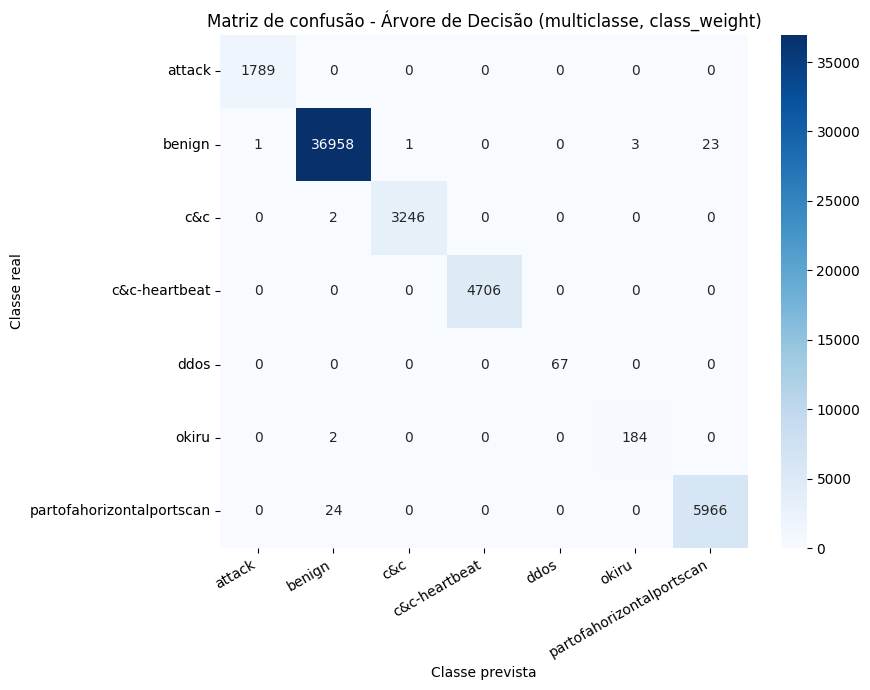

In [20]:
dt_binario_cw, y_pred_dt_bin_cw, tempo_dt_bin_cw = treinar_avaliar(
    "Árvore de Decisão (binário) - class_weight",
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste)

dt_binario_smote, y_pred_dt_bin_smote, tempo_dt_bin_smote = treinar_avaliar(
    "Árvore de Decisão (binário) - SMOTE",
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_treino_smote_bin, y_bin_treino_smote, X_teste_norm, y_bin_teste)

dt_multi_cw, y_pred_dt_multi_cw, tempo_dt_multi_cw = treinar_avaliar(
    "Árvore de Decisão (multiclasse) - class_weight",
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste)

plotar_matriz_confusao(y_multi_teste, y_pred_dt_multi_cw, dt_multi_cw.classes_,
                       "Matriz de confusão - Árvore de Decisão (multiclasse, class_weight)",
                       "matriz_confusao_dt_multiclasse.png");

### 4.3 — SVM (hiperparâmetros padrão, com cache no Drive)

[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_binario_padrao.joblib

=== SVM (binário) - class_weight (padrão) === (treino: 641.53s)
              precision    recall  f1-score   support

      benign     0.9977    0.9038    0.9484     36986
   malicious     0.8172    0.9952    0.8974     15986

    accuracy                         0.9314     52972
   macro avg     0.9074    0.9495    0.9229     52972
weighted avg     0.9432    0.9314    0.9330     52972

[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_multi_padrao.joblib

=== SVM (multiclasse) - class_weight (padrão) === (treino: 731.87s)
                           precision    recall  f1-score   support

                   attack     0.9160    1.0000    0.9562      1789
                   benign     0.9975    0.9022    0.9475     36986
                      c&c     0.5857    0.6228    0.6037      3248
            c&c-heartbeat     0.7031    1.0000    0.8257      4706
                     ddos     0

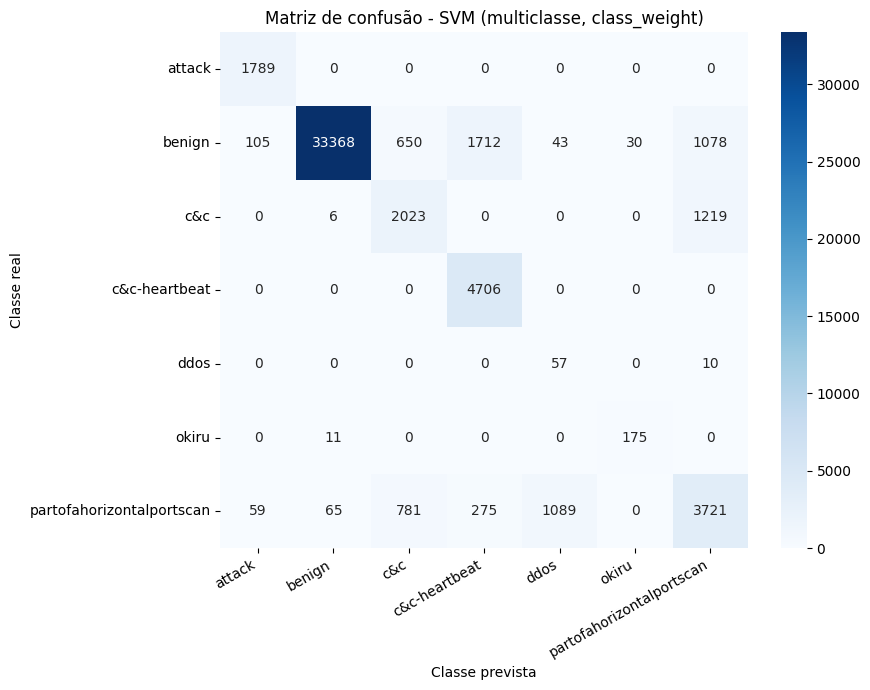

In [21]:
# SVM+SMOTE binário: executado uma vez; resultado registrado para citar no texto.
RESULTADO_SVM_SMOTE_BINARIO = {
    "tempo_treino_s": 1486.34, "acuracia": 0.93, "f1_macro": 0.93,
    "observacao": "praticamente igual ao class_weight (F1-macro 0.92), com ~2x o tempo de treino",
}

# cache_size em MB: o padrão (200) é pequeno para ~120 mil amostras
svm_binario_padrao, y_pred_svm_bin_padrao, tempo_svm_bin_padrao = treinar_avaliar(
    "SVM (binário) - class_weight (padrão)",
    SVC(kernel="rbf", class_weight="balanced", cache_size=2000),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    nome_cache="svm_binario_padrao", retreinar=RETREINAR_SVM)

svm_multi_padrao, y_pred_svm_multi_padrao, tempo_svm_multi_padrao = treinar_avaliar(
    "SVM (multiclasse) - class_weight (padrão)",
    SVC(kernel="rbf", class_weight="balanced", cache_size=2000),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    nome_cache="svm_multi_padrao", retreinar=RETREINAR_SVM)

plotar_matriz_confusao(y_multi_teste, y_pred_svm_multi_padrao, svm_multi_padrao.classes_,
                       "Matriz de confusão - SVM (multiclasse, class_weight)",
                       "matriz_confusao_svm_multiclasse.png");

### 4.4 — CNN ⬜ *(próximo passo do Roadmap)*

A implementar com Keras/TensorFlow, reaproveitando `X_treino_norm`, `X_teste_norm`, `y_bin_*` e `y_multi_*`:
- reshape do vetor de 42 atributos em matriz (ex.: 7×6, ou 7×7 com *zero-padding*);
- para a comparação estatística: 5 execuções com *seeds* diferentes (mesma arquitetura/hiperparâmetros).

## 5. Etapa 4 — Ajuste de hiperparâmetros

### 5.1 — SVM
O SVM leva ~10 min por treino no conjunto completo, então o Grid Search roda numa **subamostra estratificada**
(classes raras inteiras; benign limitado a 8.000 e as demais a 3.000), com CV estratificada de 5 folds.

- **v1:** grade C ∈ {1, 10, 100} × gamma ∈ {g₀/4, g₀, 4g₀} (g₀ = `gamma='scale'`). O melhor ponto caiu na borda da grade.
- **v2:** grade estendida (C ∈ {10, 100, 1000}, gamma ∈ {g₀, 4g₀, 16g₀}) e F1 ponderado para devolver à subamostra a prevalência natural das classes.

In [22]:
# Subamostra de tuning (a mesma para binário e multiclasse)
idx_tuning = subamostra_estratificada(y_multi_treino, cap_padrao=3000, caps={"benign": 8000})
print(f"Subamostra de tuning: {len(idx_tuning)} linhas de {len(X_treino_norm)}")
print(y_multi_treino.iloc[idx_tuning].astype(str).value_counts())

Subamostra de tuning: 20591 linhas de 123600
detailed-label
benign                       8000
partofahorizontalportscan    3000
c&c-heartbeat                3000
attack                       3000
c&c                          3000
okiru                         435
ddos                          156
Name: count, dtype: int64


In [23]:
# 5.1.1 — Tuning v1 (GridSearchCV, F1-macro simples)
def tunar_svm(nome_tarefa, y_completo, idx):
    caminho = f"{MODELOS_DIR}/svm_{nome_tarefa}_melhores_params.json"
    if os.path.exists(caminho) and not RETREINAR_SVM:
        params = json.load(open(caminho))
        print(f"[cache] parâmetros carregados: {params}")
        return params

    X_t = X_treino_norm.iloc[idx]
    y_t = y_completo.iloc[idx].astype(str)
    g0 = 1.0 / (X_t.shape[1] * np.asarray(X_t, dtype=float).var())   # = gamma='scale'
    grade = {"C": [1, 10, 100], "gamma": [g0 / 4, g0, g0 * 4]}
    gs = GridSearchCV(SVC(kernel="rbf", class_weight="balanced", cache_size=1000),
                      grade, scoring="f1_macro",
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                      n_jobs=2, refit=False, verbose=1)
    t0 = time.perf_counter()
    gs.fit(X_t, y_t)
    print(f"Grid Search ({nome_tarefa}) levou {time.perf_counter() - t0:.0f}s")

    res = pd.DataFrame(gs.cv_results_)[["param_C", "param_gamma", "mean_test_score",
                                        "std_test_score", "mean_fit_time"]] \
            .sort_values("mean_test_score", ascending=False)
    print(res.to_string(index=False))
    res.to_csv(f"{MODELOS_DIR}/svm_{nome_tarefa}_grid_resultados.csv", index=False)

    melhor = gs.cv_results_["params"][int(np.argmin(gs.cv_results_["rank_test_score"]))]
    params = {"C": float(melhor["C"]), "gamma": float(melhor["gamma"]), "gamma_scale_ref": float(g0)}
    if params["C"] in (1, 100) or params["gamma"] in (g0 / 4, g0 * 4):
        print("ATENÇÃO: o melhor ponto está na borda da grade.")
    json.dump(params, open(caminho, "w"))
    return params

params_svm_bin_v1   = tunar_svm("binario",     y_bin_treino,   idx_tuning)
params_svm_multi_v1 = tunar_svm("multiclasse", y_multi_treino, idx_tuning)

[cache] parâmetros carregados: {'C': 100.0, 'gamma': 0.24474919852435617, 'gamma_scale_ref': 0.06118729963108904}
[cache] parâmetros carregados: {'C': 100.0, 'gamma': 0.24474919852435617, 'gamma_scale_ref': 0.06118729963108904}


In [24]:
# 5.1.2 — Tuning v2 (grade estendida + F1 ponderado pela prevalência natural)
cont_full = y_multi_treino.astype(str).value_counts()
y_multi_sub = y_multi_treino.iloc[idx_tuning].astype(str)
peso_por_classe = (cont_full / y_multi_sub.value_counts()).to_dict()
w_sub = y_multi_sub.map(peso_por_classe).to_numpy(dtype=float)
print("Peso de cada classe na avaliação:", {k: round(v, 2) for k, v in peso_por_classe.items()})


def tunar_svm_ponderado(nome_tarefa, y_task, Cs, mult_gamma, sufixo="v2"):
    caminho = f"{MODELOS_DIR}/svm_{nome_tarefa}_melhores_params_{sufixo}.json"
    if os.path.exists(caminho) and not RETREINAR_SVM:
        params = json.load(open(caminho))
        print(f"[cache] parâmetros carregados: {params}")
        return params

    X_t = X_treino_norm.iloc[idx_tuning]
    y_t = y_task.iloc[idx_tuning].astype(str)
    g0 = 1.0 / (X_t.shape[1] * np.asarray(X_t, dtype=float).var())
    # folds estratificados pelo rótulo multiclasse (garante ddos/okiru em todos os folds)
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_t, y_multi_sub))
    combos = [(C, m * g0, m) for C in Cs for m in mult_gamma]

    def avaliar(C, gamma, tr, va):
        modelo = SVC(kernel="rbf", class_weight="balanced", cache_size=1000, C=C, gamma=gamma)
        modelo.fit(X_t.iloc[tr], y_t.iloc[tr])
        pred = modelo.predict(X_t.iloc[va])
        _, _, f1, _ = precision_recall_fscore_support(
            y_t.iloc[va], pred, average="macro", sample_weight=w_sub[va], zero_division=0)
        return f1

    t0 = time.perf_counter()
    scores = Parallel(n_jobs=2)(delayed(avaliar)(C, g, tr, va) for (C, g, _) in combos for (tr, va) in folds)
    print(f"Grid ({nome_tarefa}) levou {time.perf_counter() - t0:.0f}s")

    scores = np.array(scores).reshape(len(combos), len(folds))
    res = pd.DataFrame({"C": [c[0] for c in combos], "gamma_mult": [c[2] for c in combos],
                        "gamma": [c[1] for c in combos],
                        "f1_macro_ponderado": scores.mean(axis=1), "desvio": scores.std(axis=1)}
                       ).sort_values("f1_macro_ponderado", ascending=False)
    print(res.to_string(index=False))
    res.to_csv(f"{MODELOS_DIR}/svm_{nome_tarefa}_grid_resultados_{sufixo}.csv", index=False)

    melhor = res.iloc[0]
    if melhor["C"] in (min(Cs), max(Cs)) or melhor["gamma_mult"] in (min(mult_gamma), max(mult_gamma)):
        print("ATENÇÃO: melhor ponto na borda da grade.")
    params = {"C": float(melhor["C"]), "gamma": float(melhor["gamma"]),
              "gamma_mult": float(melhor["gamma_mult"]), "gamma_scale_ref": float(g0)}
    json.dump(params, open(caminho, "w"))
    return params


CS, MULT_GAMMA = [10, 100, 1000], [1, 4, 16]
params_svm_bin_v2   = tunar_svm_ponderado("binario",     y_bin_treino,   CS, MULT_GAMMA)
params_svm_multi_v2 = tunar_svm_ponderado("multiclasse", y_multi_treino, CS, MULT_GAMMA)

Peso de cada classe na avaliação: {'attack': 1.39, 'benign': 10.79, 'c&c': 2.53, 'c&c-heartbeat': 3.66, 'ddos': 1.0, 'okiru': 1.0, 'partofahorizontalportscan': 4.66}
[cache] parâmetros carregados: {'C': 1000.0, 'gamma': 0.9789967940974247, 'gamma_mult': 16.0, 'gamma_scale_ref': 0.06118729963108904}
[cache] parâmetros carregados: {'C': 1000.0, 'gamma': 0.9789967940974247, 'gamma_mult': 16.0, 'gamma_scale_ref': 0.06118729963108904}


[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_binario_tuned.joblib

=== SVM (binário) - tuning v1 === (treino: 470.85s)
              precision    recall  f1-score   support

      benign     0.9984    0.9282    0.9620     36986
   malicious     0.8571    0.9966    0.9216     15986

    accuracy                         0.9488     52972
   macro avg     0.9278    0.9624    0.9418     52972
weighted avg     0.9558    0.9488    0.9498     52972

[cache] modelo carregado: /content/drive/MyDrive/TCC/modelos/svm_multi_tuned.joblib

=== SVM (multiclasse) - tuning v1 === (treino: 301.39s)
                           precision    recall  f1-score   support

                   attack     0.9485    0.9989    0.9730      1789
                   benign     0.9990    0.9136    0.9544     36986
                      c&c     0.5674    0.9335    0.7058      3248
            c&c-heartbeat     0.9060    1.0000    0.9507      4706
                     ddos     0.0386    0.8806    0.0740 

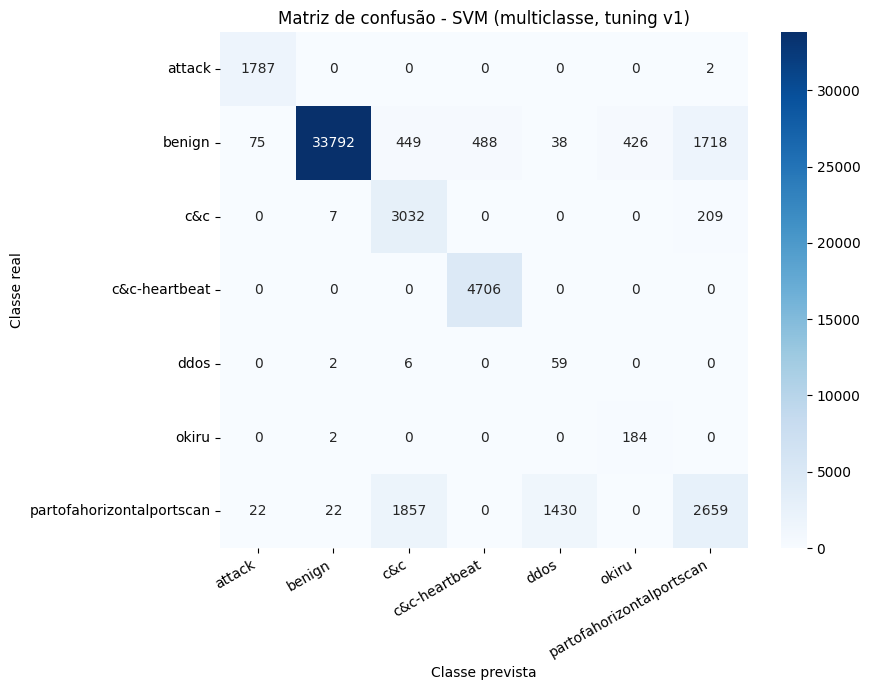

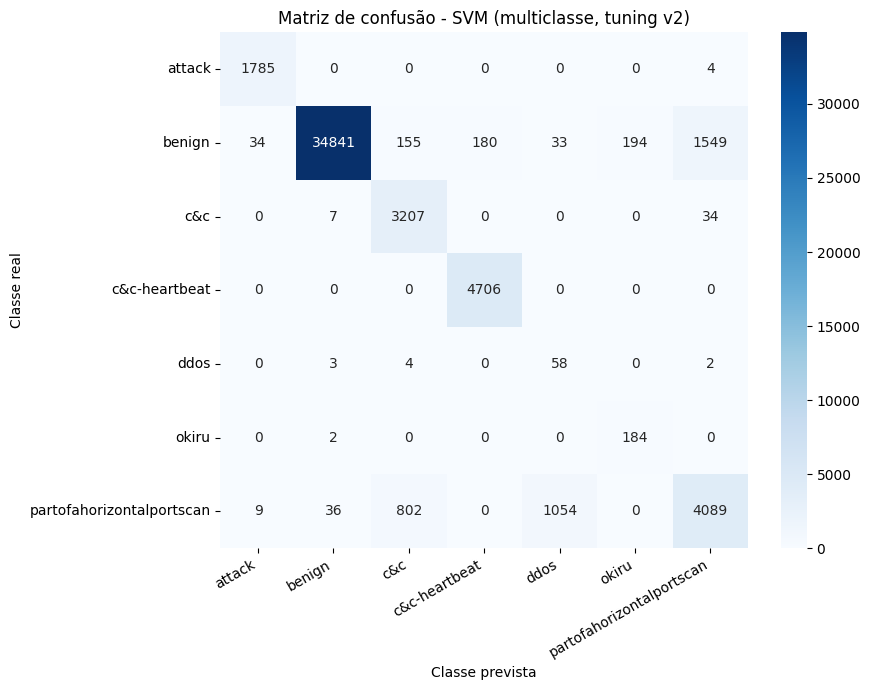

In [25]:
# 5.1.3 — Fit final no treino COMPLETO com os hiperparâmetros de cada versão (cache no Drive)
def svm_com(params):
    return SVC(kernel="rbf", class_weight="balanced", cache_size=2000, C=params["C"], gamma=params["gamma"])

svm_binario_v1, y_pred_svm_bin_v1, tempo_svm_bin_v1 = treinar_avaliar(
    "SVM (binário) - tuning v1", svm_com(params_svm_bin_v1),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    nome_cache="svm_binario_tuned", retreinar=RETREINAR_SVM)
svm_multi_v1, y_pred_svm_multi_v1, tempo_svm_multi_v1 = treinar_avaliar(
    "SVM (multiclasse) - tuning v1", svm_com(params_svm_multi_v1),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    nome_cache="svm_multi_tuned", retreinar=RETREINAR_SVM)

svm_binario_v2, y_pred_svm_bin_v2, tempo_svm_bin_v2 = treinar_avaliar(
    "SVM (binário) - tuning v2", svm_com(params_svm_bin_v2),
    X_treino_norm, y_bin_treino, X_teste_norm, y_bin_teste,
    nome_cache="svm_binario_tuned_v2", retreinar=RETREINAR_SVM)
svm_multi_v2, y_pred_svm_multi_v2, tempo_svm_multi_v2 = treinar_avaliar(
    "SVM (multiclasse) - tuning v2", svm_com(params_svm_multi_v2),
    X_treino_norm, y_multi_treino, X_teste_norm, y_multi_teste,
    nome_cache="svm_multi_tuned_v2", retreinar=RETREINAR_SVM)

plotar_matriz_confusao(y_multi_teste, y_pred_svm_multi_v1, svm_multi_v1.classes_,
                       "Matriz de confusão - SVM (multiclasse, tuning v1)",
                       "matriz_confusao_svm_multiclasse_tuned.png")
plotar_matriz_confusao(y_multi_teste, y_pred_svm_multi_v2, svm_multi_v2.classes_,
                       "Matriz de confusão - SVM (multiclasse, tuning v2)",
                       "matriz_confusao_svm_multiclasse_tuned_v2.png");

### 5.2 — Random Forest e Árvore de Decisão ⬜ *(pendente — previsto na proposta)*
Grid Search + CV estratificada de 5 folds (ex.: RF: `n_estimators`, `max_depth`; AD: `criterion`, `max_depth`).
Como ambos já estão em F1 ≈ 0,998, o objetivo aqui é cumprir o protocolo da proposta (e talvez obter modelos menores/mais rápidos sem perda de F1).

### 5.3 — CNN ⬜ *(pendente)*
Random Search restrito + holdout + *early stopping*.

## 6. Etapa 5 — Avaliação e comparação

### 6.1 — Validação cruzada estratificada de 5 folds (sobre o treino)
Todos usam `StratifiedKFold(5, shuffle=True, random_state=42)` sobre o mesmo `y` ⇒ **os folds são idênticos entre modelos** (pré-requisito para testes pareados).

In [26]:
# 6.1.1 — CV de RF e AD
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"acuracia": "accuracy", "precisao_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}

modelos_para_cv = [
    ("Random Forest - binário",         RandomForestClassifier(class_weight="balanced", **RF_KWARGS), y_bin_treino),
    ("Random Forest - multiclasse",     RandomForestClassifier(class_weight="balanced", **RF_KWARGS), y_multi_treino),
    ("Árvore de Decisão - binário",     DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), y_bin_treino),
    ("Árvore de Decisão - multiclasse", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), y_multi_treino),
]

linhas_cv, folds_cv = [], []
for nome, modelo, y in modelos_para_cv:
    t0 = time.perf_counter()
    r = cross_validate(modelo, X_treino_norm, y, cv=cv, scoring=SCORING, n_jobs=-1)
    tempo = time.perf_counter() - t0
    linha = {"modelo": nome, "tempo_total_s": round(tempo, 1)}
    for m in SCORING:
        linha[f"{m}_medio"] = r[f"test_{m}"].mean()
        linha[f"{m}_desvio"] = r[f"test_{m}"].std()
    linhas_cv.append(linha)
    folds_cv.append(pd.DataFrame({"modelo": nome, "fold": range(5), **{m: r[f"test_{m}"] for m in SCORING}}))
    print(f"{nome}: F1-macro = {linha['f1_macro_medio']:.4f} ± {linha['f1_macro_desvio']:.4f} ({tempo:.1f}s)")

df_resultados_cv = pd.DataFrame(linhas_cv)
df_folds_cv_rf_dt = pd.concat(folds_cv, ignore_index=True)
salvar_tabela(df_resultados_cv, "resultados_cv_rf_dt.csv")
salvar_tabela(df_folds_cv_rf_dt, "resultados_cv_rf_dt_folds.csv")

Random Forest - binário: F1-macro = 0.9981 ± 0.0002 (35.6s)
Random Forest - multiclasse: F1-macro = 0.9931 ± 0.0031 (46.3s)
Árvore de Decisão - binário: F1-macro = 0.9989 ± 0.0003 (11.0s)
Árvore de Decisão - multiclasse: F1-macro = 0.9970 ± 0.0021 (4.3s)
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/resultados_cv_rf_dt.csv
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/resultados_cv_rf_dt_folds.csv


In [27]:
# 6.1.2 — CV do SVM (checkpoint por fold: se a sessão cair, basta rodar de novo)
def cv_svm_checkpoint(nome_tarefa, X, y, params, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    y_str = y.astype(str)
    linhas = []
    for k, (tr, va) in enumerate(skf.split(X, y_str)):
        caminho = f"{CV_DIR}/svm_{nome_tarefa}_fold{k}.json"
        if os.path.exists(caminho) and not RETREINAR_SVM:
            linhas.append(json.load(open(caminho)))
            continue
        t0 = time.perf_counter()
        m = svm_com(params)
        m.fit(X.iloc[tr], y_str.iloc[tr])
        t_fit = time.perf_counter() - t0
        pred = m.predict(X.iloc[va])
        p, r, f, _ = precision_recall_fscore_support(y_str.iloc[va], pred, average="macro", zero_division=0)
        res = {"fold": k, "acuracia": accuracy_score(y_str.iloc[va], pred),
               "precisao_macro": p, "recall_macro": r, "f1_macro": f, "tempo_treino_s": t_fit}
        json.dump(res, open(caminho, "w"))
        linhas.append(res)
        print(f"fold {k}: F1-macro={f:.4f} acc={res['acuracia']:.4f} ({t_fit:.0f}s)")
        del m; gc.collect()

    df = pd.DataFrame(linhas)
    print(f"=== SVM {nome_tarefa} — média ± desvio (5 folds) ===")
    print(df.drop(columns="fold").agg(["mean", "std"]).T.round(4).to_string(), "\n")
    df.to_csv(f"{CV_DIR}/svm_{nome_tarefa}_cv_folds.csv", index=False)
    return df

df_cv_svm_bin_v1   = cv_svm_checkpoint("binario",        X_treino_norm, y_bin_treino,   params_svm_bin_v1)
df_cv_svm_multi_v1 = cv_svm_checkpoint("multiclasse",    X_treino_norm, y_multi_treino, params_svm_multi_v1)
df_cv_svm_bin_v2   = cv_svm_checkpoint("binario_v2",     X_treino_norm, y_bin_treino,   params_svm_bin_v2)
df_cv_svm_multi_v2 = cv_svm_checkpoint("multiclasse_v2", X_treino_norm, y_multi_treino, params_svm_multi_v2)

=== SVM binario — média ± desvio (5 folds) ===
                    mean     std
acuracia          0.9494  0.0010
precisao_macro    0.9285  0.0013
recall_macro      0.9627  0.0007
f1_macro          0.9424  0.0011
tempo_treino_s  241.4590  7.0866 

=== SVM multiclasse — média ± desvio (5 folds) ===
                    mean      std
acuracia          0.8742   0.0022
precisao_macro    0.6214   0.0026
recall_macro      0.8790   0.0132
f1_macro          0.6612   0.0031
tempo_treino_s  187.7742  11.6182 

=== SVM binario_v2 — média ± desvio (5 folds) ===
                    mean      std
acuracia          0.9613   0.0008
precisao_macro    0.9436   0.0011
recall_macro      0.9714   0.0005
f1_macro          0.9556   0.0009
tempo_treino_s  444.9675  41.0382 

=== SVM multiclasse_v2 — média ± desvio (5 folds) ===
                    mean      std
acuracia          0.9225   0.0027
precisao_macro    0.7098   0.0069
recall_macro      0.9168   0.0133
f1_macro          0.7505   0.0054
tempo_treino_s  

In [28]:
# 6.2 — Qual SVM reportar? Escolha pelo F1 da CV (treino), NÃO pelo F1 do teste.
def linha_svm(tarefa, variante, y_true, y_pred, df_cv=None):
    return {"tarefa": tarefa, "variante": variante,
            "f1_macro_cv": df_cv["f1_macro"].mean() if df_cv is not None else np.nan,
            "acuracia_teste": accuracy_score(y_true, y_pred),
            "f1_macro_teste": f1_score(y_true, y_pred, average="macro")}

df_comp_svm = pd.DataFrame([
    linha_svm("binário",     "padrão",    y_bin_teste,   y_pred_svm_bin_padrao),
    linha_svm("binário",     "tuning v1", y_bin_teste,   y_pred_svm_bin_v1,   df_cv_svm_bin_v1),
    linha_svm("binário",     "tuning v2", y_bin_teste,   y_pred_svm_bin_v2,   df_cv_svm_bin_v2),
    linha_svm("multiclasse", "padrão",    y_multi_teste, y_pred_svm_multi_padrao),
    linha_svm("multiclasse", "tuning v1", y_multi_teste, y_pred_svm_multi_v1, df_cv_svm_multi_v1),
    linha_svm("multiclasse", "tuning v2", y_multi_teste, y_pred_svm_multi_v2, df_cv_svm_multi_v2),
]).round(4)
print(df_comp_svm.to_string(index=False))
salvar_tabela(df_comp_svm, "comparacao_svm_variantes.csv")

# SVM "oficial" de cada tarefa = maior F1 médio na CV
SVMS = {"tuning v1": {"binário": (svm_binario_v1, y_pred_svm_bin_v1, tempo_svm_bin_v1, df_cv_svm_bin_v1),
                      "multiclasse": (svm_multi_v1, y_pred_svm_multi_v1, tempo_svm_multi_v1, df_cv_svm_multi_v1)},
        "tuning v2": {"binário": (svm_binario_v2, y_pred_svm_bin_v2, tempo_svm_bin_v2, df_cv_svm_bin_v2),
                      "multiclasse": (svm_multi_v2, y_pred_svm_multi_v2, tempo_svm_multi_v2, df_cv_svm_multi_v2)}}
SVM_FINAL = {}
for tarefa in ["binário", "multiclasse"]:
    candidatos = df_comp_svm[(df_comp_svm["tarefa"] == tarefa) & df_comp_svm["f1_macro_cv"].notna()]
    variante = candidatos.sort_values("f1_macro_cv", ascending=False)["variante"].iloc[0]
    SVM_FINAL[tarefa] = (variante, *SVMS[variante][tarefa])
    print(f"SVM escolhido ({tarefa}): {variante}")

     tarefa  variante  f1_macro_cv  acuracia_teste  f1_macro_teste
    binário    padrão          NaN          0.9314          0.9229
    binário tuning v1       0.9424          0.9488          0.9418
    binário tuning v2       0.9556          0.9611          0.9554
multiclasse    padrão          NaN          0.8653          0.7055
multiclasse tuning v1       0.6612          0.8725          0.6604
multiclasse tuning v2       0.7505          0.9226          0.7502
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/comparacao_svm_variantes.csv
SVM escolhido (binário): tuning v2
SVM escolhido (multiclasse): tuning v2


In [29]:
# 6.3 — Tempo de inferência (ms por amostra, média ± desvio de várias repetições)
# Para o SVM, o custo por amostra não depende do tamanho do lote: mede-se numa subamostra de 5000 linhas.
rng_inf = np.random.default_rng(RANDOM_STATE)
X_inf_svm = X_teste_norm.iloc[rng_inf.choice(len(X_teste_norm), size=min(5000, len(X_teste_norm)), replace=False)]

modelos_para_inferencia = [   # (nome, modelo, X, repetições)
    ("Random Forest - binário (class_weight)",         rf_binario_cw,      X_teste_norm, 10),
    ("Random Forest - binário (SMOTE)",                rf_binario_smote,   X_teste_norm, 10),
    ("Random Forest - multiclasse (class_weight)",     rf_multi_cw,        X_teste_norm, 10),
    ("Árvore de Decisão - binário (class_weight)",     dt_binario_cw,      X_teste_norm, 10),
    ("Árvore de Decisão - binário (SMOTE)",            dt_binario_smote,   X_teste_norm, 10),
    ("Árvore de Decisão - multiclasse (class_weight)", dt_multi_cw,        X_teste_norm, 10),
    ("SVM - binário (padrão)",                         svm_binario_padrao, X_inf_svm, 3),
    ("SVM - multiclasse (padrão)",                     svm_multi_padrao,   X_inf_svm, 3),
    ("SVM - binário (tuning v1)",                      svm_binario_v1,     X_inf_svm, 3),
    ("SVM - multiclasse (tuning v1)",                  svm_multi_v1,       X_inf_svm, 3),
    ("SVM - binário (tuning v2)",                      svm_binario_v2,     X_inf_svm, 3),
    ("SVM - multiclasse (tuning v2)",                  svm_multi_v2,       X_inf_svm, 3),
]

resultados_inferencia = []
for nome, modelo, X_inf, n_rep in modelos_para_inferencia:
    modelo.predict(X_inf.iloc[:200])                   # aquecimento
    tempos = []
    for _ in range(n_rep):
        t0 = time.perf_counter()
        modelo.predict(X_inf)
        tempos.append((time.perf_counter() - t0) / len(X_inf) * 1000)
    resultados_inferencia.append({"modelo": nome, "n_amostras_medidas": len(X_inf), "repeticoes": n_rep,
                                  "tempo_medio_ms_amostra": np.mean(tempos),
                                  "tempo_desvio_ms_amostra": np.std(tempos)})
    print(f"{nome}: {np.mean(tempos):.5f} ± {np.std(tempos):.5f} ms/amostra")

df_resultados_inferencia = pd.DataFrame(resultados_inferencia)
salvar_tabela(df_resultados_inferencia, "resultados_inferencia.csv")

Random Forest - binário (class_weight): 0.00520 ± 0.00122 ms/amostra
Random Forest - binário (SMOTE): 0.00731 ± 0.00090 ms/amostra
Random Forest - multiclasse (class_weight): 0.00534 ± 0.00026 ms/amostra
Árvore de Decisão - binário (class_weight): 0.00013 ± 0.00001 ms/amostra
Árvore de Decisão - binário (SMOTE): 0.00012 ± 0.00000 ms/amostra
Árvore de Decisão - multiclasse (class_weight): 0.00014 ± 0.00001 ms/amostra
SVM - binário (padrão): 1.55632 ± 0.09093 ms/amostra
SVM - multiclasse (padrão): 3.32951 ± 0.03919 ms/amostra
SVM - binário (tuning v1): 1.01863 ± 0.17571 ms/amostra
SVM - multiclasse (tuning v1): 2.29390 ± 0.17108 ms/amostra
SVM - binário (tuning v2): 0.72884 ± 0.14982 ms/amostra
SVM - multiclasse (tuning v2): 1.59556 ± 0.17931 ms/amostra
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/resultados_inferencia.csv


In [30]:
# 6.4 — Tabela consolidada (modelos finais, variante class_weight) — base para o capítulo de resultados
inferencia_ms = df_resultados_inferencia.set_index("modelo")["tempo_medio_ms_amostra"]
cv_rf_dt = df_resultados_cv.set_index("modelo")

def linha_final(algoritmo, tarefa, y_true, y_pred, tempo_treino, nome_inferencia, f1_cv, f1_cv_std):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"algoritmo": algoritmo, "tarefa": tarefa,
            "acuracia": accuracy_score(y_true, y_pred), "precisao_macro": p, "recall_macro": r,
            "f1_macro": f, "f1_macro_cv": f1_cv, "f1_macro_cv_desvio": f1_cv_std,
            "tempo_treino_s": tempo_treino, "inferencia_ms_amostra": inferencia_ms[nome_inferencia]}

linhas = []
for tarefa, y_te, rf_pred, rf_t, dt_pred, dt_t, rotulo in [
        ("binário", y_bin_teste, y_pred_rf_bin_cw, tempo_rf_bin_cw, y_pred_dt_bin_cw, tempo_dt_bin_cw, "binário"),
        ("multiclasse", y_multi_teste, y_pred_rf_multi_cw, tempo_rf_multi_cw, y_pred_dt_multi_cw, tempo_dt_multi_cw, "multiclasse")]:
    cv_rf = cv_rf_dt.loc[f"Random Forest - {rotulo}"]
    cv_dt = cv_rf_dt.loc[f"Árvore de Decisão - {rotulo}"]
    linhas.append(linha_final("Random Forest", tarefa, y_te, rf_pred, rf_t,
                              f"Random Forest - {rotulo} (class_weight)", cv_rf["f1_macro_medio"], cv_rf["f1_macro_desvio"]))
    linhas.append(linha_final("Árvore de Decisão", tarefa, y_te, dt_pred, dt_t,
                              f"Árvore de Decisão - {rotulo} (class_weight)", cv_dt["f1_macro_medio"], cv_dt["f1_macro_desvio"]))
    variante, _, svm_pred, svm_t, df_cv_svm = SVM_FINAL[tarefa]
    linhas.append(linha_final(f"SVM ({variante})", tarefa, y_te, svm_pred, svm_t,
                              f"SVM - {rotulo} ({variante})", df_cv_svm["f1_macro"].mean(), df_cv_svm["f1_macro"].std(ddof=0)))

df_tabela_final = pd.DataFrame(linhas).round(4)
print(df_tabela_final.to_string(index=False))
salvar_tabela(df_tabela_final, "tabela_resultados_finais.csv")

        algoritmo      tarefa  acuracia  precisao_macro  recall_macro  f1_macro  f1_macro_cv  f1_macro_cv_desvio  tempo_treino_s  inferencia_ms_amostra
    Random Forest     binário    0.9985          0.9982        0.9984    0.9983       0.9981              0.0002          6.6267                 0.0052
Árvore de Decisão     binário    0.9991          0.9990        0.9989    0.9990       0.9989              0.0003          0.6524                 0.0001
  SVM (tuning v2)     binário    0.9611          0.9434        0.9712    0.9554       0.9556              0.0008        784.6657                 0.7288
    Random Forest multiclasse    0.9987          0.9929        0.9974    0.9951       0.9931              0.0031          8.8785                 0.0053
Árvore de Decisão multiclasse    0.9989          0.9969        0.9977    0.9973       0.9970              0.0021          0.6589                 0.0001
  SVM (tuning v2) multiclasse    0.9226          0.7093        0.9235    0.7502       0.

In [31]:
# 6.5 — Teste de McNemar (complementar): RF vs AD vs SVM escolhido, no conjunto de teste
def tabela_mcnemar(y_true, pred_a, pred_b):
    acerto_a = np.asarray(pred_a) == np.asarray(y_true, dtype=str)
    acerto_b = np.asarray(pred_b) == np.asarray(y_true, dtype=str)
    return [[int(np.sum(acerto_a & acerto_b)),  int(np.sum(acerto_a & ~acerto_b))],
            [int(np.sum(~acerto_a & acerto_b)), int(np.sum(~acerto_a & ~acerto_b))]]

resultados_mcnemar = []
for tarefa, y_te, preds in [
        ("binário", y_bin_teste, {"Random Forest": y_pred_rf_bin_cw, "Árvore de Decisão": y_pred_dt_bin_cw,
                                  "SVM": SVM_FINAL["binário"][2]}),
        ("multiclasse", y_multi_teste, {"Random Forest": y_pred_rf_multi_cw, "Árvore de Decisão": y_pred_dt_multi_cw,
                                        "SVM": SVM_FINAL["multiclasse"][2]})]:
    for a, b in [("Random Forest", "SVM"), ("Random Forest", "Árvore de Decisão"), ("SVM", "Árvore de Decisão")]:
        tabela = tabela_mcnemar(y_te, preds[a], preds[b])
        resultado = mcnemar(tabela, exact=True)   # binomial exato: poucos casos discordantes
        resultados_mcnemar.append({"tarefa": tarefa, "comparacao": f"{a} vs {b}",
                                   "so_a_acerta": tabela[0][1], "so_b_acerta": tabela[1][0],
                                   "p_valor": resultado.pvalue,
                                   "significativo_5%": "SIM" if resultado.pvalue < 0.05 else "não"})

df_mcnemar = pd.DataFrame(resultados_mcnemar)
print(df_mcnemar.to_string(index=False))
salvar_tabela(df_mcnemar, "resultados_mcnemar.csv")

     tarefa                         comparacao  so_a_acerta  so_b_acerta  p_valor significativo_5%
    binário               Random Forest vs SVM         1996           14 0.000000              SIM
    binário Random Forest vs Árvore de Decisão           13           44 0.000047              SIM
    binário           SVM vs Árvore de Decisão           11         2024 0.000000              SIM
multiclasse               Random Forest vs SVM         4043            9 0.000000              SIM
multiclasse Random Forest vs Árvore de Decisão           26           38 0.168643              não
multiclasse           SVM vs Árvore de Decisão           23         4069 0.000000              SIM
[tabela] /content/drive/MyDrive/TCC/resultados/tabelas/resultados_mcnemar.csv


### 6.6 — Teste de Wilcoxon ⬜ *(pendente — previsto na proposta)*

Os valores por fold já estão salvos (`resultados_cv_rf_dt_folds.csv` e `cv_svm/svm_*_cv_folds.csv`), com folds idênticos entre modelos.

⚠️ **Atenção antes de implementar:** com apenas 5 pares, o menor p-valor bilateral possível do Wilcoxon é 2/2⁵ = **0,0625** — ou seja, ele **nunca** atinge significância a α = 0,05, mesmo que um modelo vença nos 5 folds. Opções a discutir com o orientador: usar 10 folds (p mínimo ≈ 0,002), CV repetida (ex.: 5×2), ou adotar o McNemar (6.5) como teste principal.

⬜ Incluir a CNN (5 execuções com seeds diferentes).

## 7. Experimentos complementares — validade dos resultados (Seção 4.4)

Não estavam na proposta, mas sustentam a discussão de limitações:
- **7.1 Ablação da deduplicação:** quanto vazamento treino/teste existiria sem dedup e se isso muda o F1.
- **7.2 Composição por cenário.**
- **7.3 Leave-one-scenario-out (LOSO):** generalização para um cenário de ataque nunca visto.
- **7.4 Teste com distribuição natural** das classes (sem teto de amostragem).

In [32]:
# 7.1 — Ablação da deduplicação (Random Forest binário)
RF_CW_KWARGS = dict(class_weight="balanced", **RF_KWARGS)

def f1_rf_binario(X_tr, y_tr, X_te, y_te, titulo):
    X_tr_n, X_te_n, _ = normalizar(X_tr, X_te)
    y_pred = RandomForestClassifier(**RF_CW_KWARGS).fit(X_tr_n, y_tr).predict(X_te_n)
    print(f"\n=== {titulo} ===")
    print(classification_report(y_te, y_pred, digits=4))
    return f1_score(y_te, y_pred, average="macro")

# (a) Sem a 2ª deduplicação (X já codificado, antes do drop_duplicates da Seção 3.1)
X_a_tr, X_a_te, y_a_tr, y_a_te = train_test_split(
    X, y_binario, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_binario)
n_ov_a, pct_ov_a = sobreposicao(X_a_tr, X_a_te)
f1_a = f1_rf_binario(X_a_tr, y_a_tr, X_a_te, y_a_te, "RF binário - sem a 2ª dedup")

# (b) Sem NENHUMA deduplicação: amostragem direta do bruto (réplica provável do baseline)
if not os.path.exists(CAMINHO_BRUTO):
    raise FileNotFoundError(f"{CAMINHO_BRUTO} não existe — rode a Seção 2 com REPROCESSAR_DADOS_BRUTOS=True.")
dataset_bruto = ds.dataset(CAMINHO_BRUTO, format="parquet")
CONTAGENS_BRUTO = contar_classes_bruto()          # contagem real, lida do arquivo
print("Linhas por classe no bruto:", CONTAGENS_BRUTO)

rng = np.random.default_rng(RANDOM_STATE)
partes = []
for classe, total in CONTAGENS_BRUTO.items():
    p_manter = min(1.0, CAP_POR_CLASSE * 1.3 / total)   # margem de 30%, depois corta no valor exato
    df_classe = amostrar_classe_bruto(dataset_bruto, classe, p_manter, rng)
    if len(df_classe) > CAP_POR_CLASSE:
        df_classe = df_classe.sample(n=CAP_POR_CLASSE, random_state=RANDOM_STATE)
    print(f"{classe}: {total:,} brutas -> {len(df_classe):,} amostradas")
    partes.append(df_classe)
    gc.collect()
df_sem_dedup = pd.concat(partes, ignore_index=True)
del partes; gc.collect()

X_b, y_b_bin, _ = separar_X_y(preprocessar_features(df_sem_dedup)[0])
X_b_tr, X_b_te, y_b_tr, y_b_te = train_test_split(
    X_b, y_b_bin, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_b_bin)
n_ov_b, pct_ov_b = sobreposicao(X_b_tr, X_b_te)
f1_b = f1_rf_binario(X_b_tr, y_b_tr, X_b_te, y_b_te, "RF binário - sem nenhuma dedup")
del df_sem_dedup, X_b; gc.collect()

# (c) Pipeline atual (dedup completo) = modelo da Seção 4.1
f1_c = f1_score(y_bin_teste, y_pred_rf_bin_cw, average="macro")

resumo_ablacao = pd.DataFrame([
    {"experimento": "(a) Sem a 2ª dedup (X codificado)",                "overlap_treino_teste_%": pct_ov_a, "f1_macro": f1_a},
    {"experimento": "(b) Sem nenhuma dedup (réplica do baseline)",      "overlap_treino_teste_%": pct_ov_b, "f1_macro": f1_b},
    {"experimento": "(c) Pipeline atual (dedup por classe + dedup em X)", "overlap_treino_teste_%": pct_overlap, "f1_macro": f1_c},
]).round(4)
print(resumo_ablacao.to_string(index=False))
salvar_tabela(resumo_ablacao, "resumo_ablacao_dedup.csv")


=== RF binário - sem a 2ª dedup ===
              precision    recall  f1-score   support

      benign     0.9991    0.9989    0.9990     37062
   malicious     0.9974    0.9979    0.9977     15996

    accuracy                         0.9986     53058
   macro avg     0.9982    0.9984    0.9983     53058
weighted avg     0.9986    0.9986    0.9986     53058

Linhas por classe no bruto: {'okiru': 13626744, 'partofahorizontalportscan': 7040929, 'benign': 505082, 'c&c-heartbeat': 15688, 'c&c': 14944, 'ddos': 14394, 'attack': 5962}
okiru: 13,626,744 brutas -> 20,000 amostradas
partofahorizontalportscan: 7,040,929 brutas -> 20,000 amostradas
benign: 505,082 brutas -> 20,000 amostradas
c&c-heartbeat: 15,688 brutas -> 15,688 amostradas
c&c: 14,944 brutas -> 14,944 amostradas
ddos: 14,394 brutas -> 14,394 amostradas
attack: 5,962 brutas -> 5,962 amostradas

=== RF binário - sem nenhuma dedup ===
              precision    recall  f1-score   support

      benign     0.9990    0.9947    0.99

In [33]:
# 7.2 — Composição de cada cenário (% por classe, após dedup)
composicao_por_cenario = pd.crosstab(origem_cenario_dedup, y_multiclasse_dedup, normalize="index") * 100
print(origem_cenario_dedup.value_counts(), "\n")
print(composicao_por_cenario.round(1))
salvar_tabela(composicao_por_cenario.round(2).reset_index(), "composicao_por_cenario.csv")

origem_cenario
capture_1_1     107872
capture_9_1      23821
capture_36_1     17347
capture_3_1      13740
capture_34_1      7711
capture_8_1       4309
capture_5_1       1195
capture_4_1        452
capture_7_1        125
Name: count, dtype: int64 

detailed-label  attack  benign   c&c  c&c-heartbeat  ddos  okiru  \
origem_cenario                                                     
capture_1_1        0.0    90.3   0.0            0.0   0.0    0.0   
capture_34_1       0.0    10.1  87.0            0.0   2.9    0.0   
capture_36_1       0.0     6.0   0.0           90.4   0.0    3.6   
capture_3_1       43.4    25.6   0.1            0.0   0.0    0.0   
capture_4_1        0.0   100.0   0.0            0.0   0.0    0.0   
capture_5_1        0.0   100.0   0.0            0.0   0.0    0.0   
capture_7_1        0.0   100.0   0.0            0.0   0.0    0.0   
capture_8_1        0.0     4.6  95.4            0.0   0.0    0.0   
capture_9_1        0.0    78.1   0.0            0.0   0.0    0.0   

d

In [34]:
# 7.3 — Leave-one-scenario-out (RF): treina sem um cenário de ataque e testa nele
# Cenários maliciosos/benignos são detectados automaticamente a partir dos dados.
rotulo_bin_str = y_binario_dedup.astype(str)
cenarios_maliciosos = sorted(origem_cenario_dedup[rotulo_bin_str == "malicious"].unique())
cenarios_benignos   = sorted(set(origem_cenario_dedup.unique()) - set(cenarios_maliciosos))
print("Maliciosos:", cenarios_maliciosos, "| Só benignos:", cenarios_benignos)

# Os cenários só-benignos são divididos uma vez em treino/teste e reaproveitados em todas as rodadas
idx_benigno = origem_cenario_dedup.index[origem_cenario_dedup.isin(cenarios_benignos)]
idx_ben_tr, idx_ben_te = train_test_split(idx_benigno, test_size=TEST_SIZE, random_state=RANDOM_STATE)

resultados_loso = []
for cenario in cenarios_maliciosos:
    idx_tr = origem_cenario_dedup.index[origem_cenario_dedup.isin([c for c in cenarios_maliciosos if c != cenario])]
    idx_te = origem_cenario_dedup.index[origem_cenario_dedup == cenario]
    idx_tr, idx_te = idx_tr.append(idx_ben_tr), idx_te.append(idx_ben_te)

    X_tr_n, X_te_n, _ = normalizar(X_dedup.loc[idx_tr], X_dedup.loc[idx_te])
    linha = {"cenario_holdout": cenario, "n_teste": len(idx_te),
             "classes_no_teste_ausentes_no_treino": sorted(set(y_multiclasse_dedup.loc[idx_te].astype(str))
                                                          - set(y_multiclasse_dedup.loc[idx_tr].astype(str)))}
    print(f"\n######## {cenario} fora do treino ########")
    for tarefa, y in [("binario", y_binario_dedup), ("multiclasse", y_multiclasse_dedup)]:
        y_tr, y_te = y.loc[idx_tr].astype(str), y.loc[idx_te].astype(str)
        y_pred = RandomForestClassifier(**RF_CW_KWARGS).fit(X_tr_n, y_tr).predict(X_te_n)
        linha[f"acuracia_{tarefa}"] = accuracy_score(y_te, y_pred)
        linha[f"f1_macro_{tarefa}"] = f1_score(y_te, y_pred, average="macro", zero_division=0)
        print(f"--- {tarefa}: acc={linha[f'acuracia_{tarefa}']:.4f} | F1-macro={linha[f'f1_macro_{tarefa}']:.4f}")
        print(pd.crosstab(y_te, y_pred, rownames=["Real"], colnames=["Previsto"]))
    resultados_loso.append(linha)

df_loso = pd.DataFrame(resultados_loso).round(4)
print("\n", df_loso.to_string(index=False))
salvar_tabela(df_loso, "resultados_loso.csv")

Maliciosos: ['capture_1_1', 'capture_34_1', 'capture_36_1', 'capture_3_1', 'capture_8_1', 'capture_9_1'] | Só benignos: ['capture_4_1', 'capture_5_1', 'capture_7_1']

######## capture_1_1 fora do treino ########
--- binario: acc=0.7282 | F1-macro=0.6143
Previsto   benign  malicious
Real                        
benign      68929      28984
malicious     480      10011
--- multiclasse: acc=0.6901 | F1-macro=0.1760
Previsto                   attack  benign    c&c  c&c-heartbeat  ddos  okiru  \
Real                                                                           
benign                          1   68912  10107           2423     2   3975   
c&c                             0       1      0              0     0      0   
partofahorizontalportscan       3     479   4114              0     0      0   

Previsto                   partofahorizontalportscan  
Real                                                  
benign                                         12493  
c&c               

In [35]:
# 7.4 — Teste com distribuição NATURAL das classes (sem teto de amostragem)
# Amostra ~30 mil linhas do bruto na proporção real de cada classe, remove as que já
# existem no treino e avalia os modelos binários já treinados.
# Importante: a codificação usa o vocabulário de 'history' aprendido no pipeline principal.
TAMANHO_TESTE_NATURAL = 30_000
total_bruto = sum(CONTAGENS_BRUTO.values())
hashes_treino = set(pd.util.hash_pandas_object(X_treino, index=False))
rng = np.random.default_rng(RANDOM_STATE)

def codificar_como_treino(df_bruto):
    X_ext, y_bin_ext, _ = separar_X_y(preprocessar_features(df_bruto, CATEGORIAS_HISTORY)[0])
    X_ext = X_ext.reindex(columns=X_treino.columns, fill_value=0).astype(X_treino.dtypes.to_dict())
    return X_ext, y_bin_ext

partes = []
for classe, total in CONTAGENS_BRUTO.items():
    n_alvo = round(TAMANHO_TESTE_NATURAL * total / total_bruto)
    if n_alvo == 0:
        print(f"{classe}: proporção natural resulta em 0 exemplos -- pulando")
        continue
    df_classe = amostrar_classe_bruto(dataset_bruto, classe, min(1.0, n_alvo * 1.5 / total), rng)
    if df_classe.empty:
        continue
    X_tmp, _ = codificar_como_treino(df_classe)
    nao_visto = (~pd.util.hash_pandas_object(X_tmp, index=False).isin(hashes_treino)).values
    df_classe = df_classe.loc[nao_visto].reset_index(drop=True)
    if len(df_classe) > n_alvo:
        df_classe = df_classe.sample(n=n_alvo, random_state=RANDOM_STATE)
    print(f"{classe}: alvo={n_alvo} | obtido após remover overlap com o treino={len(df_classe)}")
    partes.append(df_classe)
    gc.collect()

df_bruto_natural = pd.concat(partes, ignore_index=True)
del partes; gc.collect()
X_teste_natural, y_bin_teste_natural = codificar_como_treino(df_bruto_natural)
print("\nDistribuição do teste natural:")
print(rotulo_multiclasse(df_bruto_natural["detailed-label"]).value_counts())
del df_bruto_natural

X_teste_natural_norm = X_teste_natural.copy()
X_teste_natural_norm[COLUNAS_NUMERICAS] = scaler.transform(X_teste_natural[COLUNAS_NUMERICAS])

resultados_dist_natural = []
for nome, modelo in {"Random Forest": rf_binario_cw, "Árvore de Decisão": dt_binario_cw,
                     f"SVM ({SVM_FINAL['binário'][0]})": SVM_FINAL["binário"][1]}.items():
    y_pred = modelo.predict(X_teste_natural_norm)
    print(f"\n=== {nome} — teste com distribuição natural ===")
    print(classification_report(y_bin_teste_natural, y_pred, digits=4, zero_division=0))
    resultados_dist_natural.append({"modelo": nome,
                                    "f1_macro": f1_score(y_bin_teste_natural, y_pred, average="macro")})

df_dist_natural = pd.DataFrame(resultados_dist_natural).round(4)
print(df_dist_natural.to_string(index=False))
salvar_tabela(df_dist_natural, "resultados_distribuicao_natural.csv")

okiru: alvo=19262 | obtido após remover overlap com o treino=0
partofahorizontalportscan: alvo=9952 | obtido após remover overlap com o treino=9952
benign: alvo=714 | obtido após remover overlap com o treino=297
c&c-heartbeat: alvo=22 | obtido após remover overlap com o treino=10
c&c: alvo=21 | obtido após remover overlap com o treino=6
ddos: alvo=20 | obtido após remover overlap com o treino=1
attack: alvo=8 | obtido após remover overlap com o treino=6

Distribuição do teste natural:
detailed-label
partofahorizontalportscan    9952
benign                        297
c&c-heartbeat                  10
c&c                             6
attack                          6
ddos                            1
Name: count, dtype: Int64

=== Random Forest — teste com distribuição natural ===
              precision    recall  f1-score   support

      benign     0.9867    1.0000    0.9933       297
   malicious     1.0000    0.9996    0.9998      9975

    accuracy                         0.9996  